# DASCM 2026 — Dataset 3
# Smart Logistics Supply Chain Dataset
## Exploratory Data Analysis for `Logistics_Delay`

**Project objective:** Understand the supplied smart-logistics dataset, identify relevant predictors of `Logistics_Delay`, exclude variables that reveal the target, explore every important variable, investigate relationships, and develop evidence-based brainstorming hypotheses.

---

## 1. Dataset task

The project asks us to predict **`Logistics_Delay`** from structured logistics, route, traffic, vehicle, and shipment variables.

The instruction explicitly states:

> **Exclude `Shipment_Status` and `Logistics_Delay_Reason` if they reveal the target.**

Accordingly, this notebook treats both columns as **target-leakage / post-outcome variables** and excludes them from the relevant predictor set and all predictive relationship analysis. They are inspected only in a dedicated leakage-audit section so that the reason for exclusion is transparent.

### Required EDA structure

1. Understand the big picture of the dataset
2. Understand each variable
3. Understand relationships among variables
4. Detect missing values and outliers
5. Produce statistical and graphical evidence
6. Brainstorm findings, hypotheses, and questions
7. Support methodological choices with external references

### Important provenance limitation

The supplied CSV contains the data values and column names, but it does **not** contain documentation identifying a publisher, collection organization, survey protocol, sensor platform, sampling frame, or original URL. Therefore, this notebook does **not** invent a collection method or claim that the data came from Kaggle or another named source.

Where the source file is silent, the notebook explicitly marks the point as **not documented in the supplied source**. This preserves the distinction between source-derived facts and interpretation.


## 2. What is this dataset about?

Based strictly on the supplied columns, the dataset represents **structured logistics/supply-chain observations recorded at timestamps**. Each row contains an `Asset_ID`, geographic coordinates, inventory information, environmental conditions, traffic status, waiting time, customer/transaction variables, asset utilization, demand forecast, and a binary `Logistics_Delay` outcome.

The dataset therefore supports an analytical question of the form:

> **Given the operational, geographic, traffic, asset, demand, and transaction conditions available for a logistics observation, can we understand and eventually predict whether a logistics delay occurs?**

The dataset contains **1,000 observations and 16 columns** in the supplied CSV. The target `Logistics_Delay` is binary (`0`/`1`).

### Interpretation boundary

The names of the variables support the operational interpretation above. However, the supplied file does not define exact units or collection instruments for every field. Where units are not explicit in the column name or values, the notebook describes the variable conservatively rather than inventing a measurement protocol.


## 3. Data provenance and collection-method assessment

### What can be established from the supplied source?

- File supplied: `smart_logistics_dataset.csv`
- The observations contain timestamps from **2024-01-01 through 2024-12-30**.
- `Timestamp` is unique for every row in the supplied file.
- There are 10 distinct asset identifiers (`Truck_1`–`Truck_10`).
- The file has no duplicate complete rows.
- Missing values occur in `Logistics_Delay_Reason`.

### What cannot be established?

The CSV does not document:

- the original data publisher;
- whether observations came from real sensors, transactions, simulation, or manual entry;
- the sampling procedure;
- the geographic reference system for the latitude/longitude values;
- the exact units for every numeric variable;
- the operational definition used to assign `Logistics_Delay`.

**Therefore, no unsupported collection story is presented.**

### External methodological context

For the later modeling stage, scikit-learn documents standard approaches for encoding categorical features, imputing missing values, scaling variables, and handling outliers. Its documentation also emphasizes that preprocessing should be handled as part of a modeling pipeline to avoid leakage from evaluation data. The current notebook uses those principles as methodological context but performs **EDA only**, not final predictive modeling.


## 4. Data dictionary

| Column | Role / type | Description based on supplied source |
|---|---|---|
| `Timestamp` | Datetime/context | Date and time associated with the logistics observation. |
| `Asset_ID` | Categorical identifier | Identifier of the logistics asset; the supplied values are `Truck_1` to `Truck_10`. |
| `Latitude` | Numerical / geographic | Latitude coordinate associated with the observation. |
| `Longitude` | Numerical / geographic | Longitude coordinate associated with the observation. |
| `Inventory_Level` | Numerical | Inventory level recorded for the observation. |
| `Shipment_Status` | **Excluded — leakage audit** | Shipment outcome/status. It is excluded because it can reveal whether a logistics delay has already occurred. |
| `Temperature` | Numerical | Temperature recorded for the observation. |
| `Humidity` | Numerical | Humidity recorded for the observation. |
| `Traffic_Status` | Categorical predictor | Traffic condition category. Supplied values are `Clear`, `Heavy`, and `Detour`. |
| `Waiting_Time` | Numerical | Waiting time associated with the logistics observation. |
| `User_Transaction_Amount` | Numerical | Transaction amount associated with the observation. |
| `User_Purchase_Frequency` | Numerical | Purchase frequency associated with the observation. |
| `Logistics_Delay_Reason` | **Excluded — leakage audit** | Recorded reason for a logistics delay. Because it directly describes the target outcome, it is excluded from predictive features. |
| `Asset_Utilization` | Numerical | Utilization level of the logistics asset. |
| `Demand_Forecast` | Numerical | Forecast demand associated with the observation. |
| `Logistics_Delay` | **Target** | Binary outcome to be understood/predicted: `0` or `1`. |

### Relevant variables selected for the analytical task

**Predictor candidates retained for EDA/modeling:**

- `Timestamp` → derive time features such as month, day-of-week, and hour
- `Asset_ID`
- `Latitude`
- `Longitude`
- `Inventory_Level`
- `Temperature`
- `Humidity`
- `Traffic_Status`
- `Waiting_Time`
- `User_Transaction_Amount`
- `User_Purchase_Frequency`
- `Asset_Utilization`
- `Demand_Forecast`

**Excluded from predictors:**

- `Shipment_Status`
- `Logistics_Delay_Reason`

**Target:**

- `Logistics_Delay`

`Asset_ID` is retained for descriptive analysis because it can reveal asset-level variation, but its identifier-like nature should be considered carefully before final modeling. `Timestamp` itself is transformed into interpretable temporal features rather than treated as an arbitrary string.


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pandas.plotting import parallel_coordinates

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.figsize"] = (10, 6)

BASE_DIR = Path.cwd()
DATA_PATH = Path("../MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/data/smart_logistics_dataset.csv")
PLOT_DIR = BASE_DIR / "plots-3"
PLOT_DIR.mkdir(exist_ok=True)

TARGET = "Logistics_Delay"
LEAKAGE_COLS = ["Shipment_Status", "Logistics_Delay_Reason"]

def save_plot(name):
    path = PLOT_DIR / f"{name}.png"
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved: {path}")

def show_save(name):
    save_plot(name)
    plt.show()


In [2]:
# Load the supplied dataset exactly as provided
df = pd.read_csv(DATA_PATH)

print(f"File: {DATA_PATH.name}")
print(f"Shape: {df.shape}")
display(df.head())


File: smart_logistics_dataset.csv
Shape: (1000, 16)


,Timestamp,Asset_ID,Latitude,Longitude,Inventory_Level,Shipment_Status,Temperature,Humidity,Traffic_Status,Waiting_Time,User_Transaction_Amount,User_Purchase_Frequency,Logistics_Delay_Reason,Asset_Utilization,Demand_Forecast,Logistics_Delay
0,2024-03-20 00:11:14,Truck_7,-65.7383,11.2497,390,Delayed,27.0,67.8,Detour,38,320,4,NaN,60.1,285,1
1,2024-10-30 07:53:51,Truck_6,22.2748,-131.7086,491,In Transit,22.5,54.3,Heavy,16,439,7,Weather,80.9,174,1
2,2024-07-29 18:42:48,Truck_10,54.9232,79.5455,190,In Transit,25.2,62.2,Detour,34,355,3,NaN,99.2,260,0
3,2024-10-28 00:50:54,Truck_9,42.3900,-1.4788,330,Delivered,25.4,52.3,Heavy,37,227,5,Traffic,97.4,160,1
4,2024-09-27 15:52:58,Truck_7,-65.8477,47.9468,480,Delayed,20.5,57.2,Clear,56,197,6,NaN,71.6,270,1


# Part A — Understand the big picture

## 5. Dataset dimensions and structural profile

The first step is to establish the scale, time coverage, uniqueness, variable types, and target structure before interpreting individual relationships.


In [3]:
print("Rows:", f"{len(df):,}")
print("Columns:", df.shape[1])
print("Complete duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["Timestamp"].duplicated().sum())
print("Unique Asset_ID values:", df["Asset_ID"].nunique())

display(pd.DataFrame({
    "Metric": [
        "Rows", "Columns", "Duplicate complete rows",
        "Unique timestamps", "Unique assets", "Target missing values"
    ],
    "Value": [
        len(df), df.shape[1], df.duplicated().sum(),
        df["Timestamp"].nunique(), df["Asset_ID"].nunique(), df[TARGET].isna().sum()
    ]
}))


Rows: 1,000
Columns: 16
Complete duplicate rows: 0
Duplicate timestamps: 0
Unique Asset_ID values: 10


,Metric,Value
0,Rows,1000
1,Columns,16
2,Duplicate complete rows,0
3,Unique timestamps,1000
4,Unique assets,10
5,Target missing values,0


In [4]:
df["Timestamp_parsed"] = pd.to_datetime(df["Timestamp"], errors="coerce")

print("Timestamp minimum:", df["Timestamp_parsed"].min())
print("Timestamp maximum:", df["Timestamp_parsed"].max())
print("Invalid timestamps:", df["Timestamp_parsed"].isna().sum())

target_counts = df[TARGET].value_counts().sort_index()
target_share = (target_counts / len(df) * 100).round(2)

display(pd.DataFrame({
    "count": target_counts,
    "percentage": target_share
}))


Timestamp minimum: 2024-01-01 11:37:57
Timestamp maximum: 2024-12-30 20:21:58
Invalid timestamps: 0


,count,percentage
Logistics_Delay,,
0,434,43.4
1,566,56.6


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/01_target_distribution.png


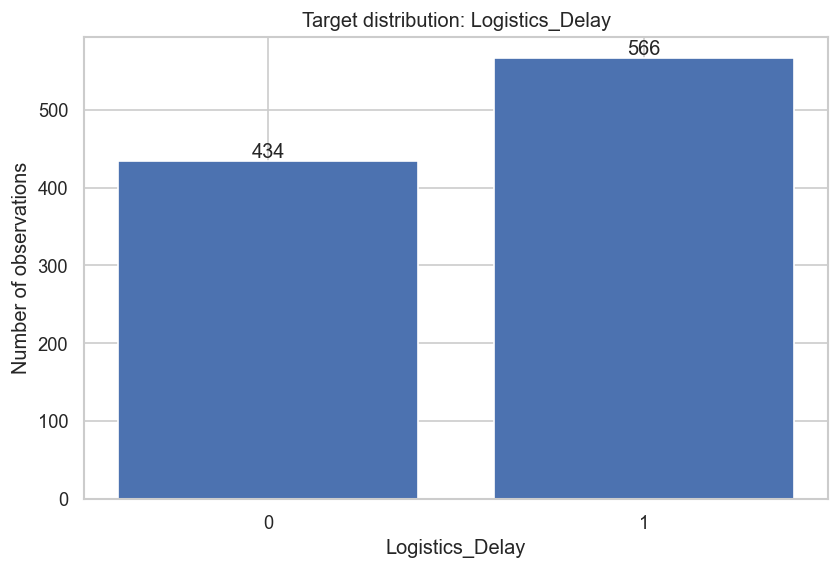

In [5]:
# Target distribution
plt.figure(figsize=(8, 5))
bars = plt.bar(target_counts.index.astype(str), target_counts.values)
plt.xlabel("Logistics_Delay")
plt.ylabel("Number of observations")
plt.title("Target distribution: Logistics_Delay")
for bar, value in zip(bars, target_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, value, f"{value:,}", ha="center", va="bottom")
show_save("01_target_distribution")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/02_target_share.png


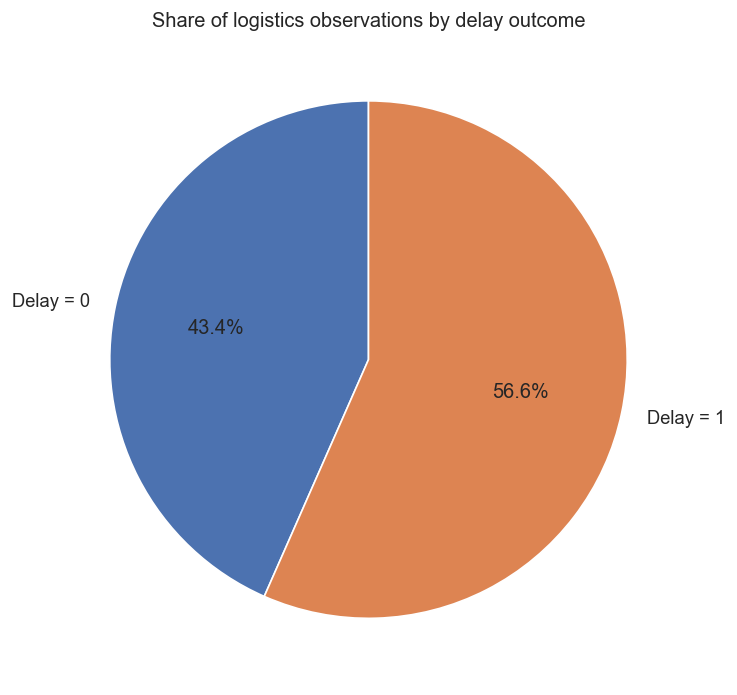

In [6]:
# Target share
plt.figure(figsize=(7, 7))
plt.pie(
    target_counts.values,
    labels=[f"Delay = {i}" for i in target_counts.index],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Share of logistics observations by delay outcome")
show_save("02_target_share")


## 6. Data types and missing values

Missingness is reported before any preprocessing. No values are imputed or removed in this EDA notebook.


In [7]:
dtype_table = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": [str(df[c].dtype) for c in df.columns],
    "Non_Null": [df[c].notna().sum() for c in df.columns],
    "Missing": [df[c].isna().sum() for c in df.columns],
    "Missing_%": [(df[c].isna().mean()*100) for c in df.columns],
    "Unique": [df[c].nunique(dropna=True) for c in df.columns]
})
display(dtype_table.round(2))


,Column,Data_Type,Non_Null,Missing,Missing_%,Unique
0,Timestamp,object,1000,0,0.0,1000
1,Asset_ID,object,1000,0,0.0,10
2,Latitude,float64,1000,0,0.0,1000
3,Longitude,float64,1000,0,0.0,1000
4,Inventory_Level,int64,1000,0,0.0,366
5,Shipment_Status,object,1000,0,0.0,3
6,Temperature,float64,1000,0,0.0,121
7,Humidity,float64,1000,0,0.0,291
8,Traffic_Status,object,1000,0,0.0,3
9,Waiting_Time,int64,1000,0,0.0,51


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/03_missing_value_rate.png


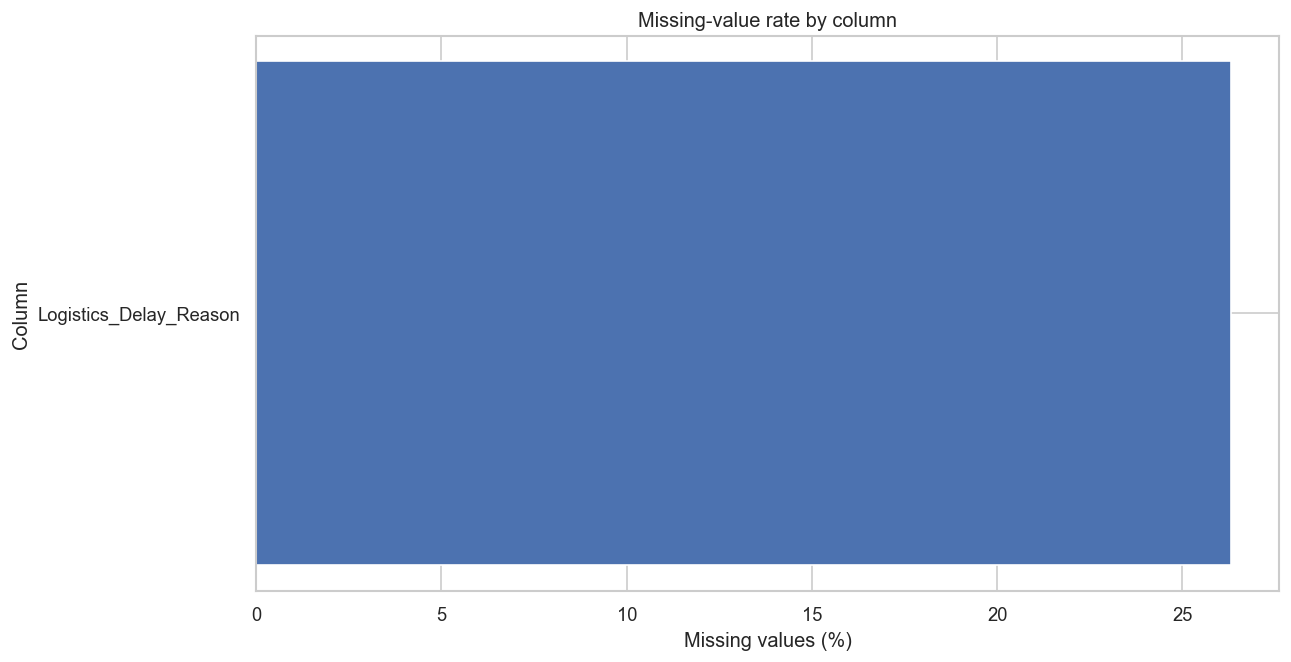

In [8]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = df.isna().mean().sort_values(ascending=False) * 100

plt.figure(figsize=(11, 6))
mask = missing > 0
plt.barh(missing.index[mask].astype(str), missing_pct[mask].values)
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Missing-value rate by column")
show_save("03_missing_value_rate")


### Missingness interpretation

The supplied data contain missing values in `Logistics_Delay_Reason`. This column is excluded from predictive analysis anyway because it is a post-outcome reason field. The fact that missingness occurs in an excluded leakage column means it does not create a missing-value problem for the retained predictor set.

This is an EDA observation, not a claim about why the values are missing; the supplied CSV does not document the missingness mechanism.


# Part B — Understand each variable

## 7. Numerical statistical profile

The numerical variables are summarized with count, mean, standard deviation, quartiles, minimum, and maximum. These statistics establish scale and identify variables that may require closer distribution/outlier inspection.


In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_predictors = [
    "Latitude", "Longitude", "Inventory_Level", "Temperature", "Humidity",
    "Waiting_Time", "User_Transaction_Amount", "User_Purchase_Frequency",
    "Asset_Utilization", "Demand_Forecast"
]

numeric_summary = df[numeric_predictors].describe().T
numeric_summary["skewness"] = df[numeric_predictors].skew()
numeric_summary["missing"] = df[numeric_predictors].isna().sum()
display(numeric_summary.round(3))


,count,mean,std,min,25%,50%,75%,max,skewness,missing
Latitude,1000.0,-1.360,51.997,-89.792,-46.168,-4.503,44.503,89.870,0.034,0
Longitude,1000.0,0.837,104.844,-179.820,-88.448,0.678,88.156,179.924,-0.002,0
Inventory_Level,1000.0,297.915,113.555,100.000,201.000,299.000,399.000,500.000,0.016,0
Temperature,1000.0,23.894,3.322,18.000,21.200,23.800,26.600,30.000,0.015,0
Humidity,1000.0,65.042,8.754,50.000,57.200,65.200,72.400,80.000,-0.055,0
Waiting_Time,1000.0,35.062,14.478,10.000,23.000,35.000,49.000,60.000,0.006,0
User_Transaction_Amount,1000.0,299.055,117.788,100.000,191.750,301.500,405.000,500.000,0.002,0
User_Purchase_Frequency,1000.0,5.513,2.935,1.000,3.000,6.000,8.000,10.000,-0.003,0
Asset_Utilization,1000.0,79.599,11.631,60.000,69.475,79.250,89.425,100.000,0.044,0
Demand_Forecast,1000.0,199.284,59.921,100.000,144.000,202.000,251.250,300.000,-0.017,0


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/04_numerical_histograms_kde.png


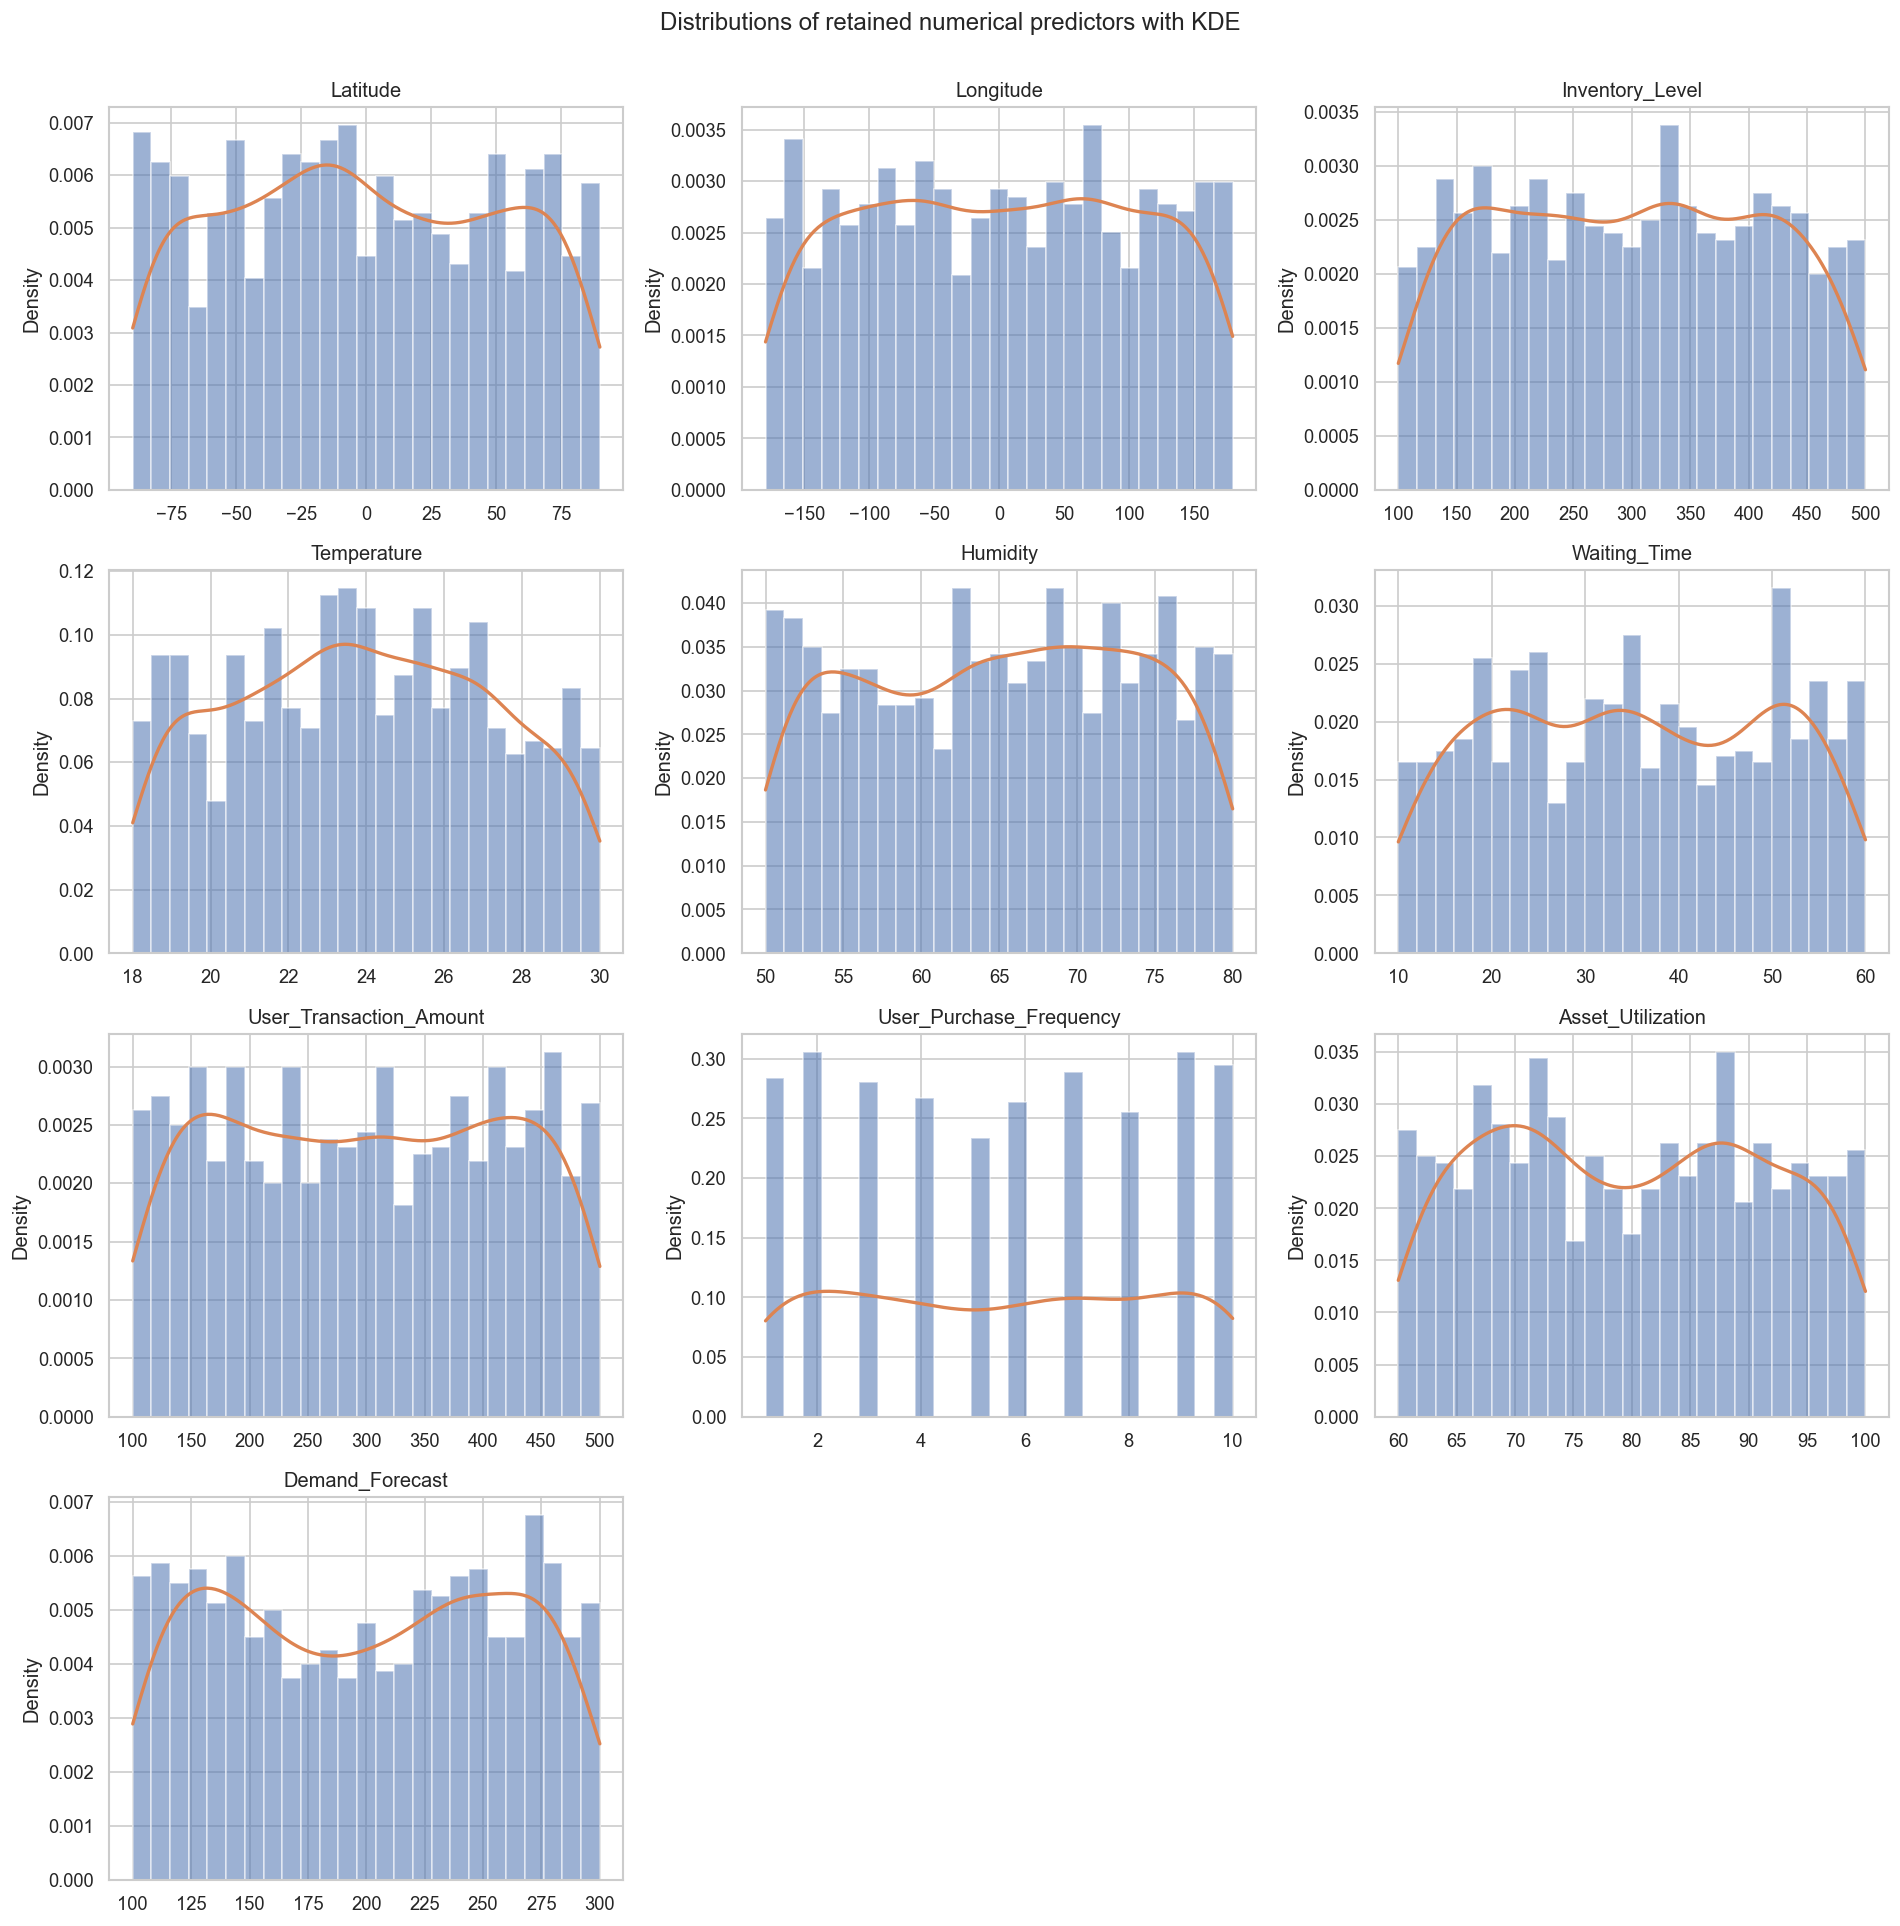

In [10]:
# Histograms with KDE for all retained numerical predictors
ncols = 3
nrows = int(np.ceil(len(numeric_predictors) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4*nrows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_predictors):
    values = df[col].dropna().to_numpy()
    ax.hist(values, bins=25, density=True, alpha=0.55)
    if len(values) > 1 and np.std(values) > 0:
        kde = stats.gaussian_kde(values)
        x = np.linspace(values.min(), values.max(), 250)
        ax.plot(x, kde(x), linewidth=2)
    ax.set_title(col)
    ax.set_ylabel("Density")

for ax in axes[len(numeric_predictors):]:
    ax.axis("off")

fig.suptitle("Distributions of retained numerical predictors with KDE", y=1.002)
plt.tight_layout()
show_save("04_numerical_histograms_kde")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/05_numerical_boxplots.png


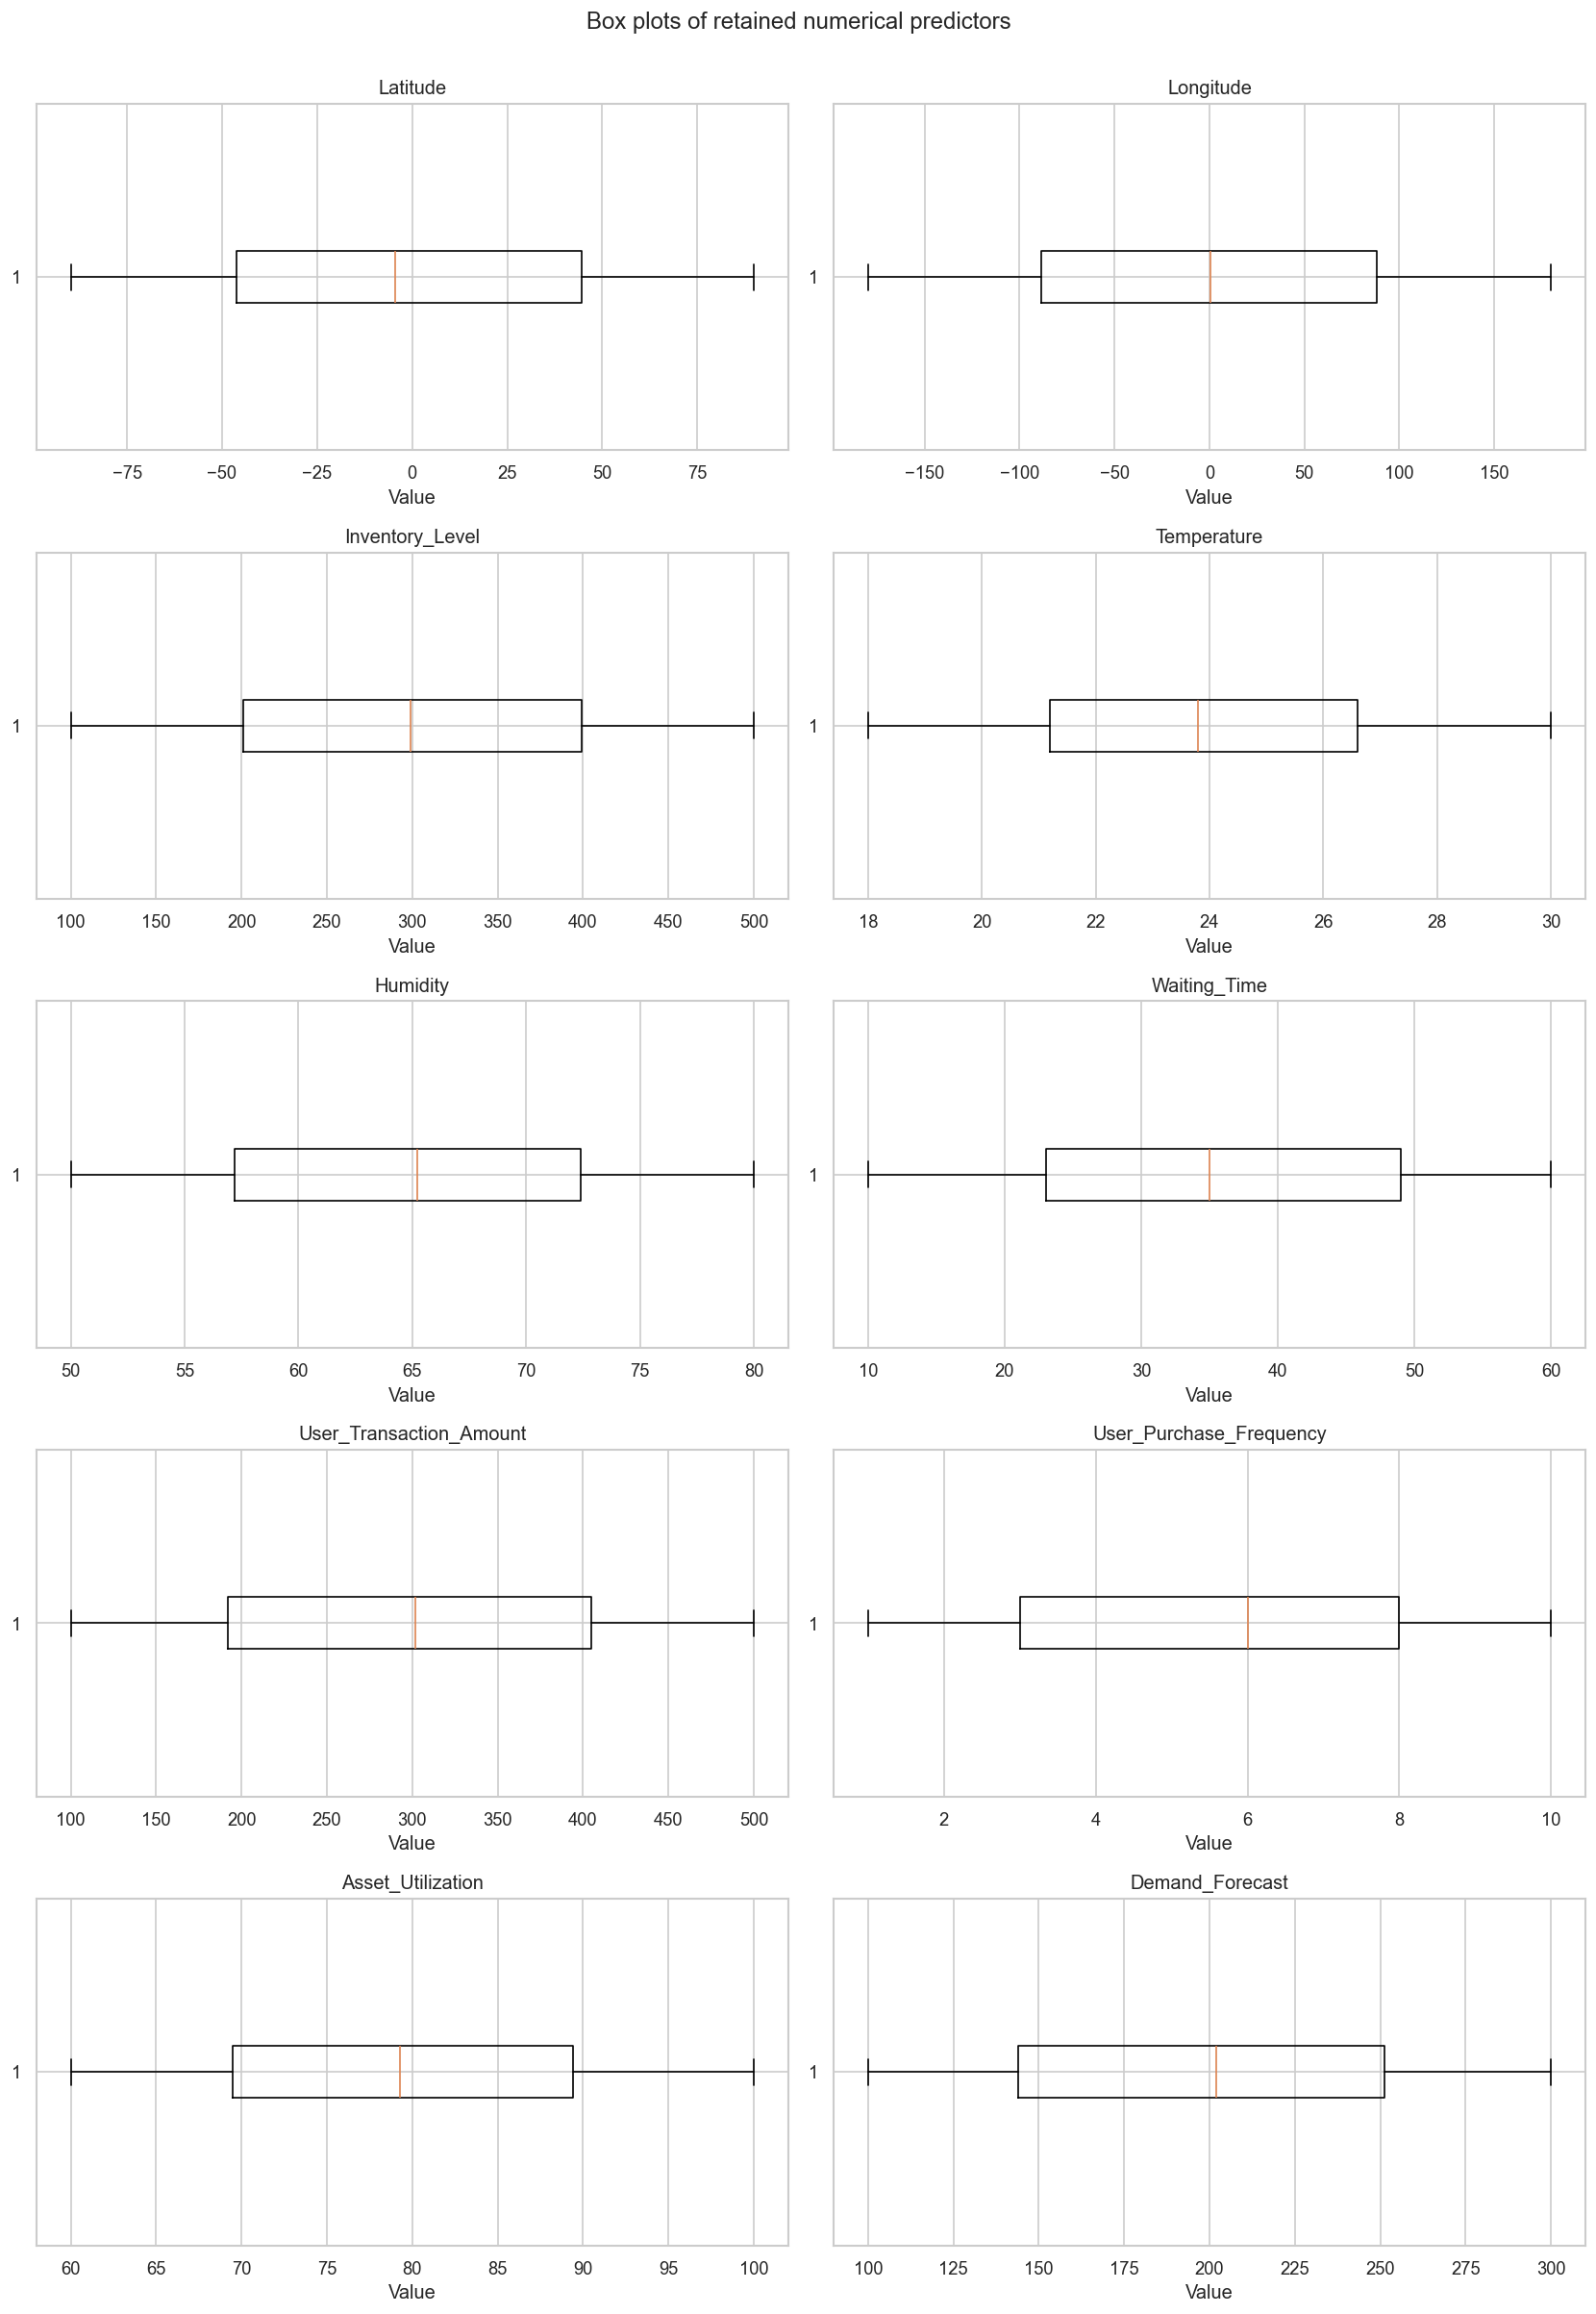

In [11]:
# Box plots for numerical predictors
ncols = 2
nrows = int(np.ceil(len(numeric_predictors) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4*nrows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_predictors):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(col)
    ax.set_xlabel("Value")

for ax in axes[len(numeric_predictors):]:
    ax.axis("off")

fig.suptitle("Box plots of retained numerical predictors", y=1.002)
plt.tight_layout()
show_save("05_numerical_boxplots")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/06_violin_plots_by_target.png


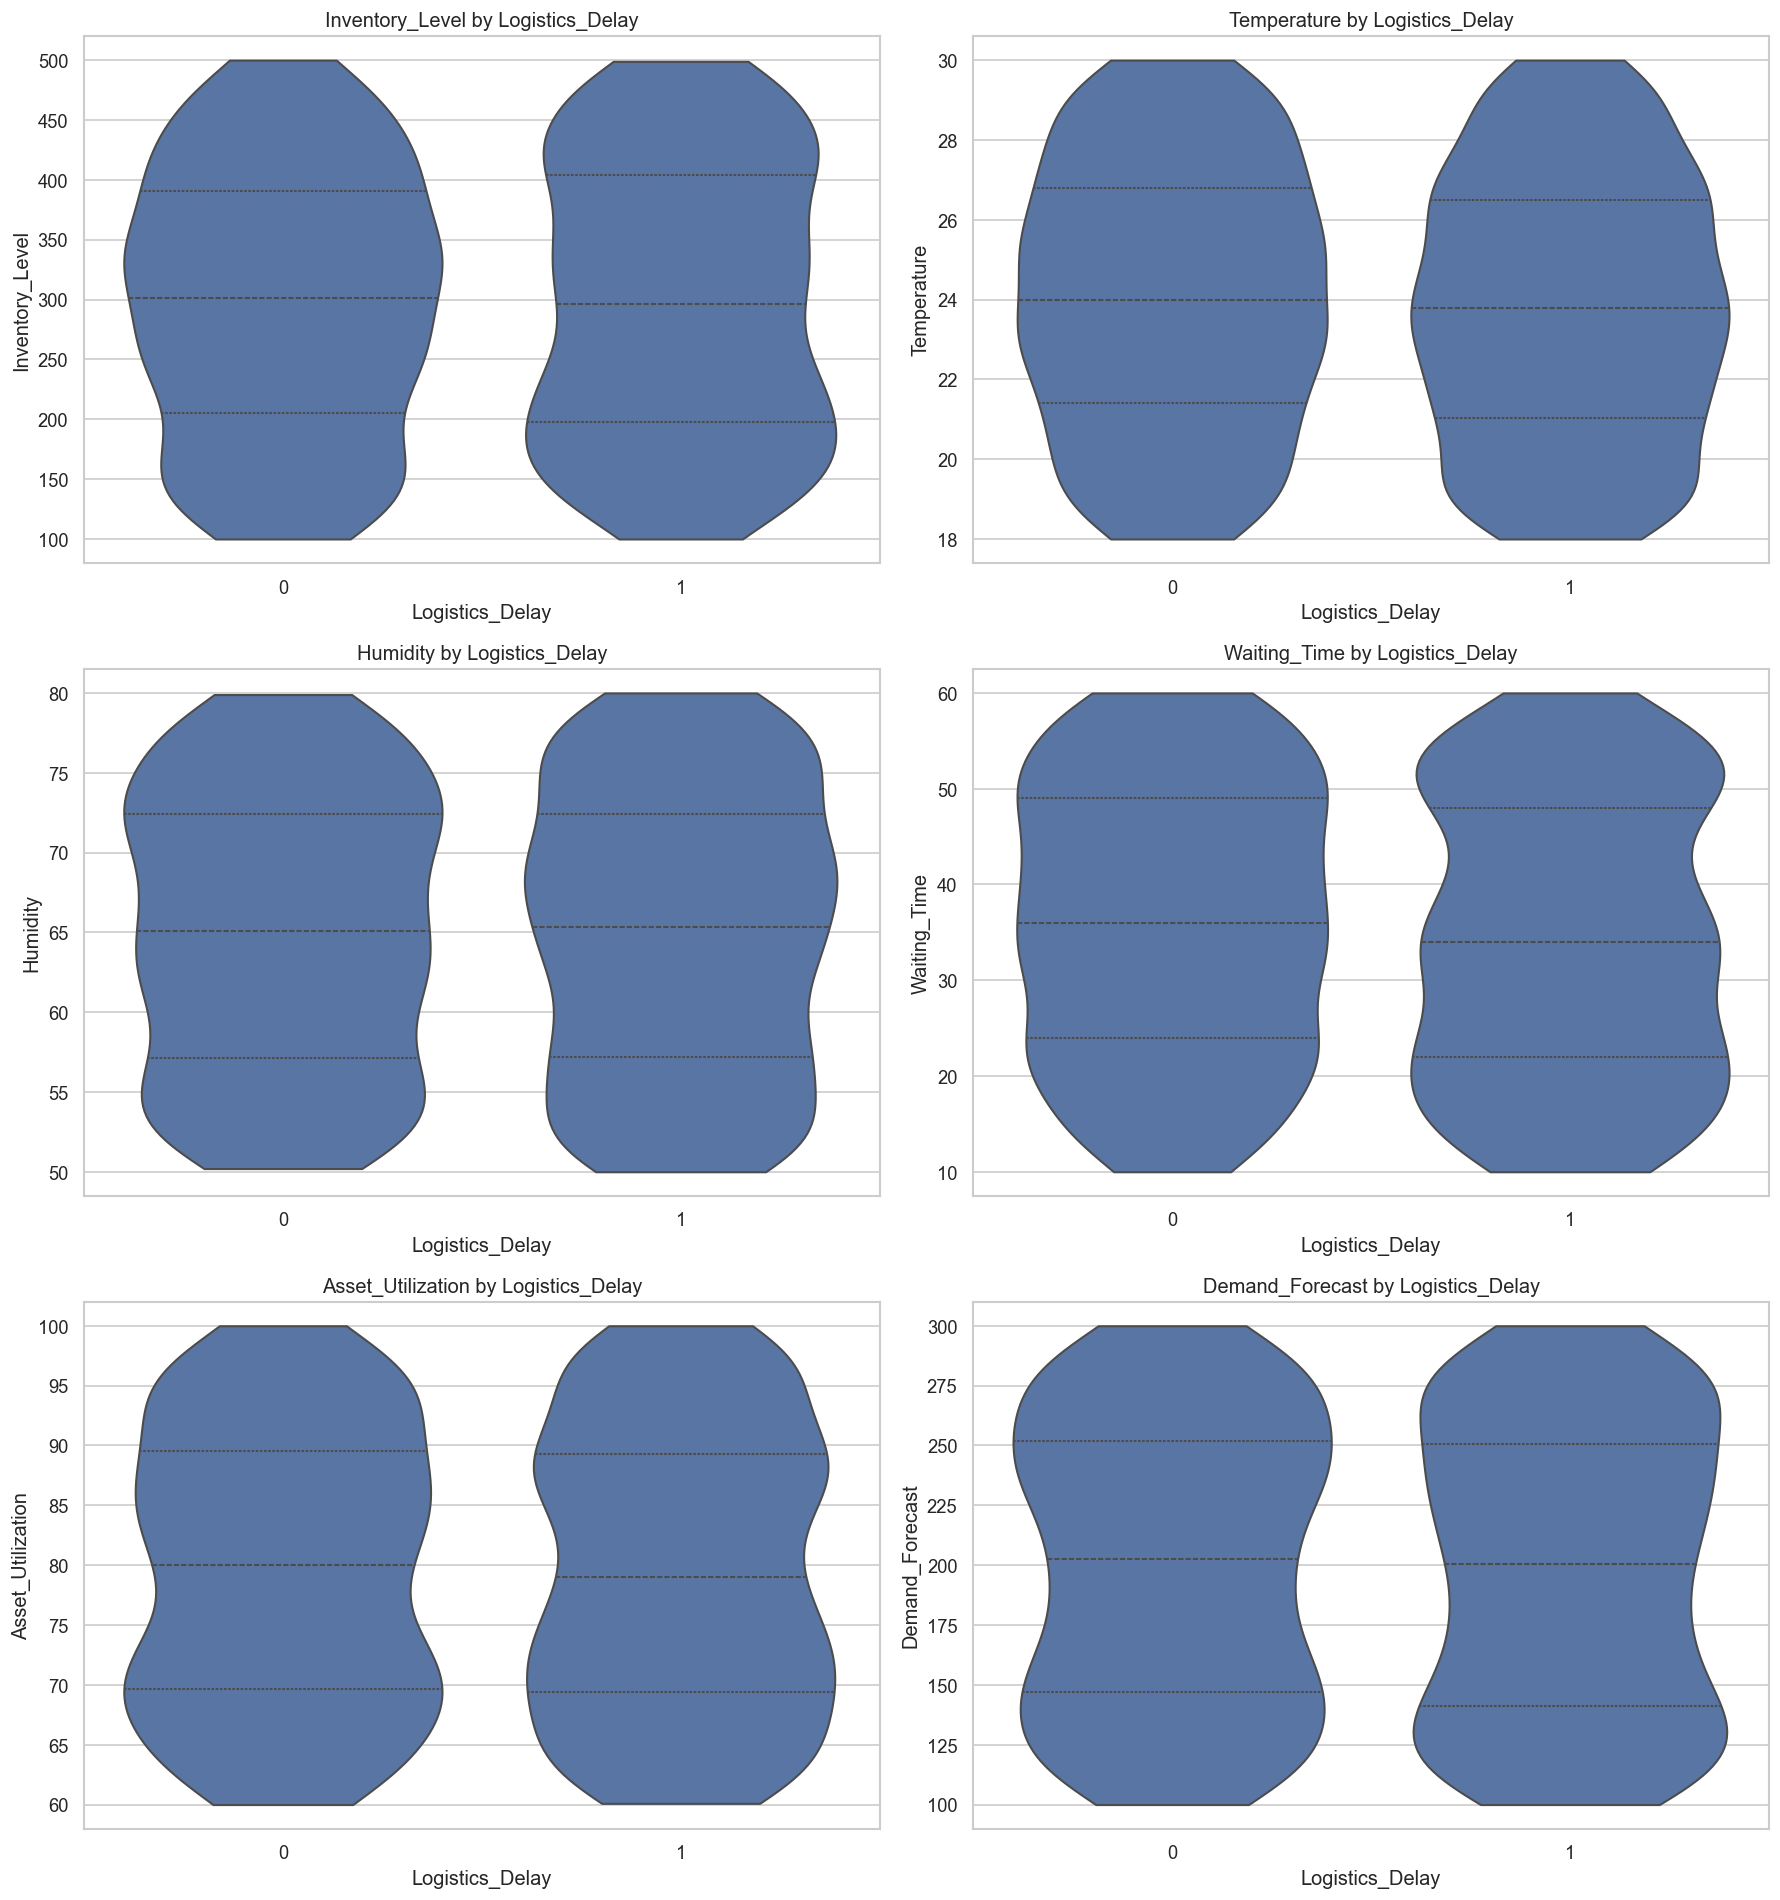

In [12]:
# Violin plots for selected operational predictors
violin_cols = [
    "Inventory_Level", "Temperature", "Humidity", "Waiting_Time",
    "Asset_Utilization", "Demand_Forecast"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 16))
for ax, col in zip(axes.ravel(), violin_cols):
    sns.violinplot(data=df, x=TARGET, y=col, ax=ax, inner="quartile", cut=0)
    ax.set_title(f"{col} by Logistics_Delay")
    ax.set_xlabel("Logistics_Delay")

plt.tight_layout()
show_save("06_violin_plots_by_target")


## 8. Categorical variables

The main retained categorical variables are `Asset_ID` and `Traffic_Status`. The excluded leakage columns are deliberately not used as predictors.

`Asset_ID` is analyzed descriptively because different assets can exhibit different observed delay rates, but the identifier should not automatically be interpreted as a causal operational feature.


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/07_distribution_asset_id.png


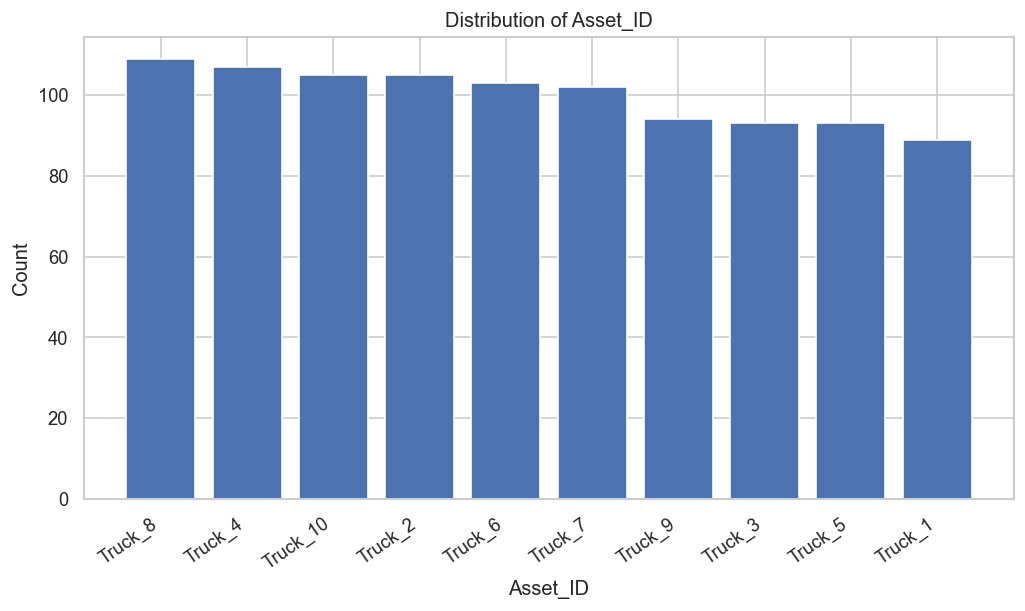

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/07_distribution_traffic_status.png


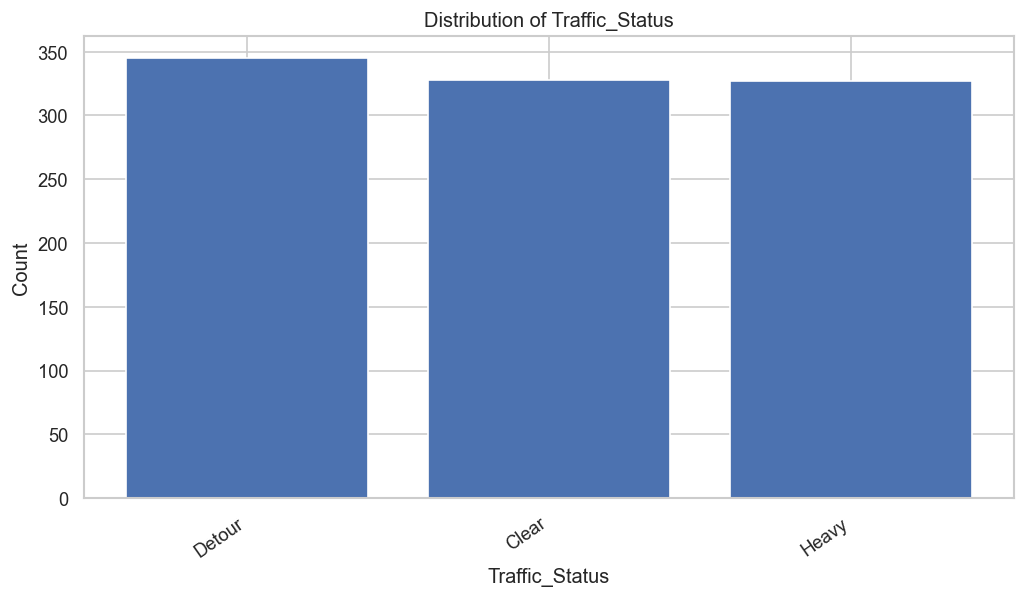

In [13]:
categorical_predictors = ["Asset_ID", "Traffic_Status"]

for col in categorical_predictors:
    counts = df[col].value_counts()
    plt.figure(figsize=(10, 5))
    plt.bar(counts.index.astype(str), counts.values)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=35, ha="right")
    show_save(f"07_distribution_{col.lower()}")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/08_traffic_status_share.png


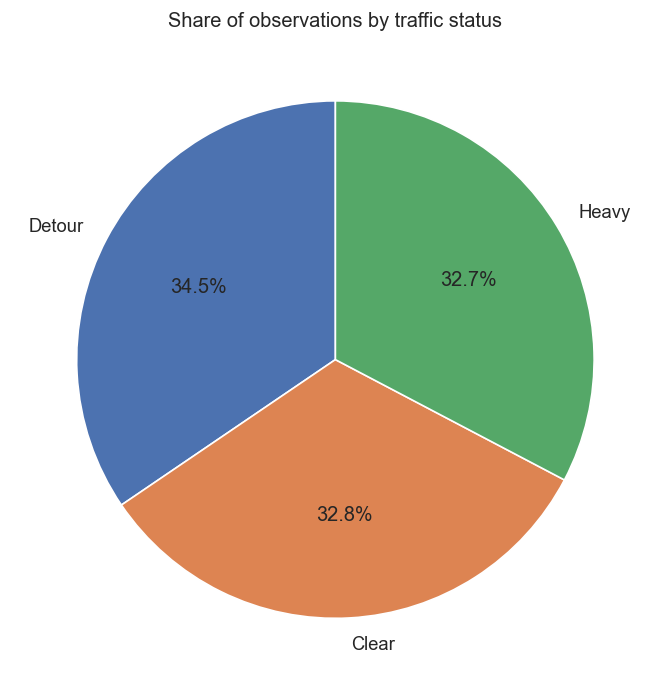

In [14]:
# Traffic status share
traffic_counts = df["Traffic_Status"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(traffic_counts.values, labels=traffic_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of observations by traffic status")
show_save("08_traffic_status_share")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/09_delay_rate_by_traffic.png


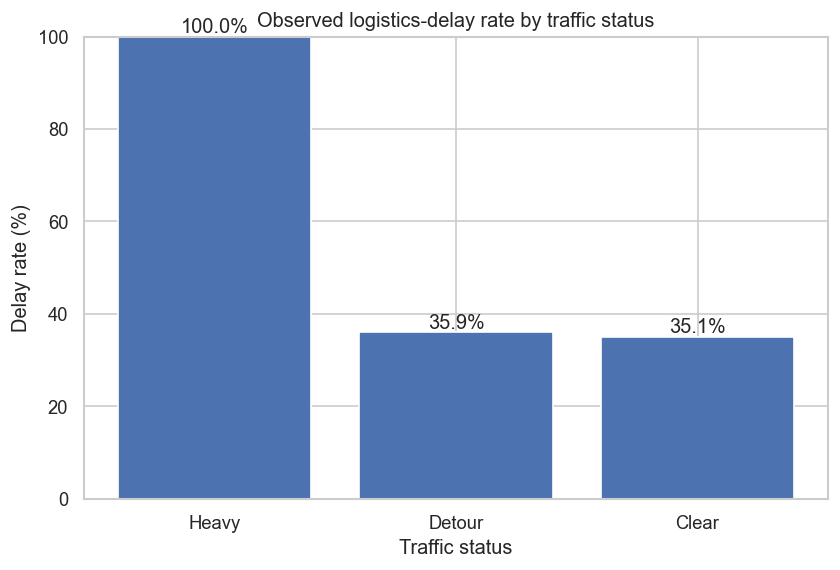

In [15]:
# Target rate by traffic status
traffic_delay_rate = df.groupby("Traffic_Status")[TARGET].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(8, 5))
bars = plt.bar(traffic_delay_rate.index, traffic_delay_rate.values)
plt.ylabel("Delay rate (%)")
plt.xlabel("Traffic status")
plt.title("Observed logistics-delay rate by traffic status")
plt.ylim(0, 100)
for bar, value in zip(bars, traffic_delay_rate.values):
    plt.text(bar.get_x()+bar.get_width()/2, value, f"{value:.1f}%", ha="center", va="bottom")
show_save("09_delay_rate_by_traffic")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/10_delay_rate_by_asset.png


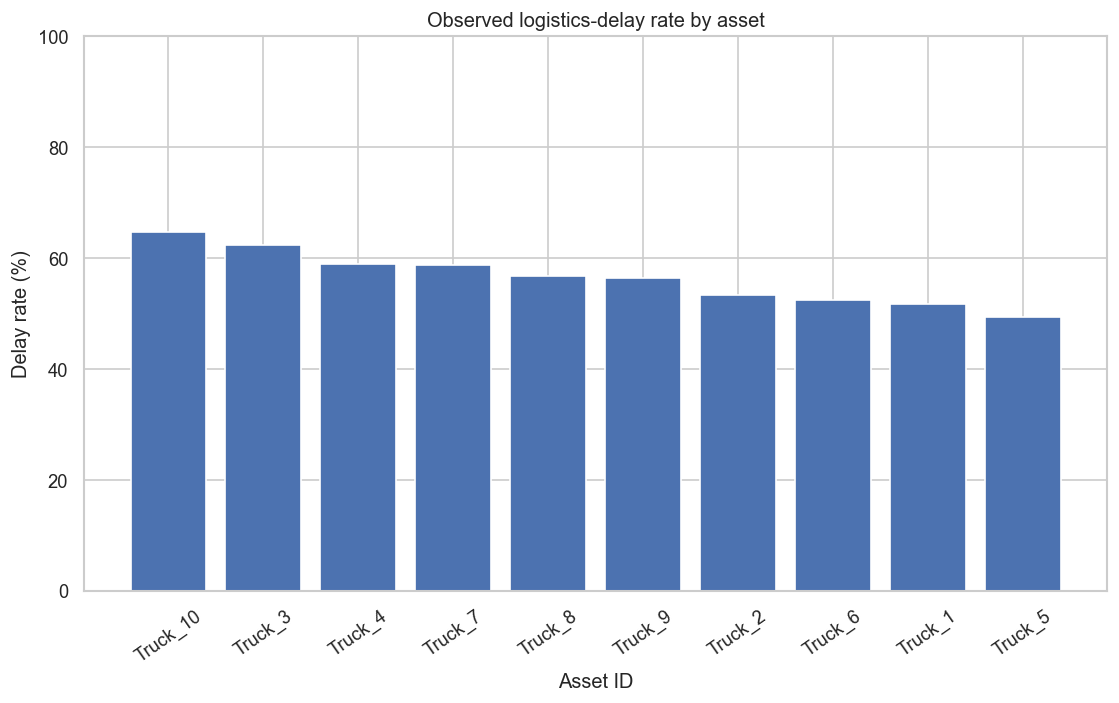

In [16]:
# Target rate by asset
asset_delay_rate = df.groupby("Asset_ID")[TARGET].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(11, 6))
bars = plt.bar(asset_delay_rate.index, asset_delay_rate.values)
plt.ylabel("Delay rate (%)")
plt.xlabel("Asset ID")
plt.title("Observed logistics-delay rate by asset")
plt.ylim(0, 100)
plt.xticks(rotation=35)
show_save("10_delay_rate_by_asset")


# Part C — Outlier detection

## 9. IQR-based outlier screening

The 1.5×IQR rule is used as a **screening method**, not an automatic deletion rule. In logistics data, unusually high waiting time, demand, utilization, or transaction values may represent genuine operational states.

The scikit-learn documentation notes that outliers can affect scaling and that robust approaches can be useful when outliers are present. This supports investigating unusual observations before deciding whether any preprocessing is appropriate. [scikit-learn preprocessing documentation](https://scikit-learn.org/stable/modules/preprocessing.html)


In [17]:
outlier_records = []

for col in numeric_predictors:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)

    outlier_records.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Fence": lower,
        "Upper_Fence": upper,
        "Outlier_Count": int(mask.sum()),
        "Outlier_%": float(mask.mean()*100)
    })

outlier_table = pd.DataFrame(outlier_records).sort_values("Outlier_%", ascending=False)
display(outlier_table.round(3))


,Feature,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Outlier_Count,Outlier_%
0,Latitude,-46.168,44.503,90.671,-182.174,180.509,0,0.0
1,Longitude,-88.448,88.156,176.605,-353.355,353.063,0,0.0
2,Inventory_Level,201.000,399.000,198.000,-96.000,696.000,0,0.0
3,Temperature,21.200,26.600,5.400,13.100,34.700,0,0.0
4,Humidity,57.200,72.400,15.200,34.400,95.200,0,0.0
5,Waiting_Time,23.000,49.000,26.000,-16.000,88.000,0,0.0
6,User_Transaction_Amount,191.750,405.000,213.250,-128.125,724.875,0,0.0
7,User_Purchase_Frequency,3.000,8.000,5.000,-4.500,15.500,0,0.0
8,Asset_Utilization,69.475,89.425,19.950,39.550,119.350,0,0.0
9,Demand_Forecast,144.000,251.250,107.250,-16.875,412.125,0,0.0


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/11_iqr_outlier_rates.png


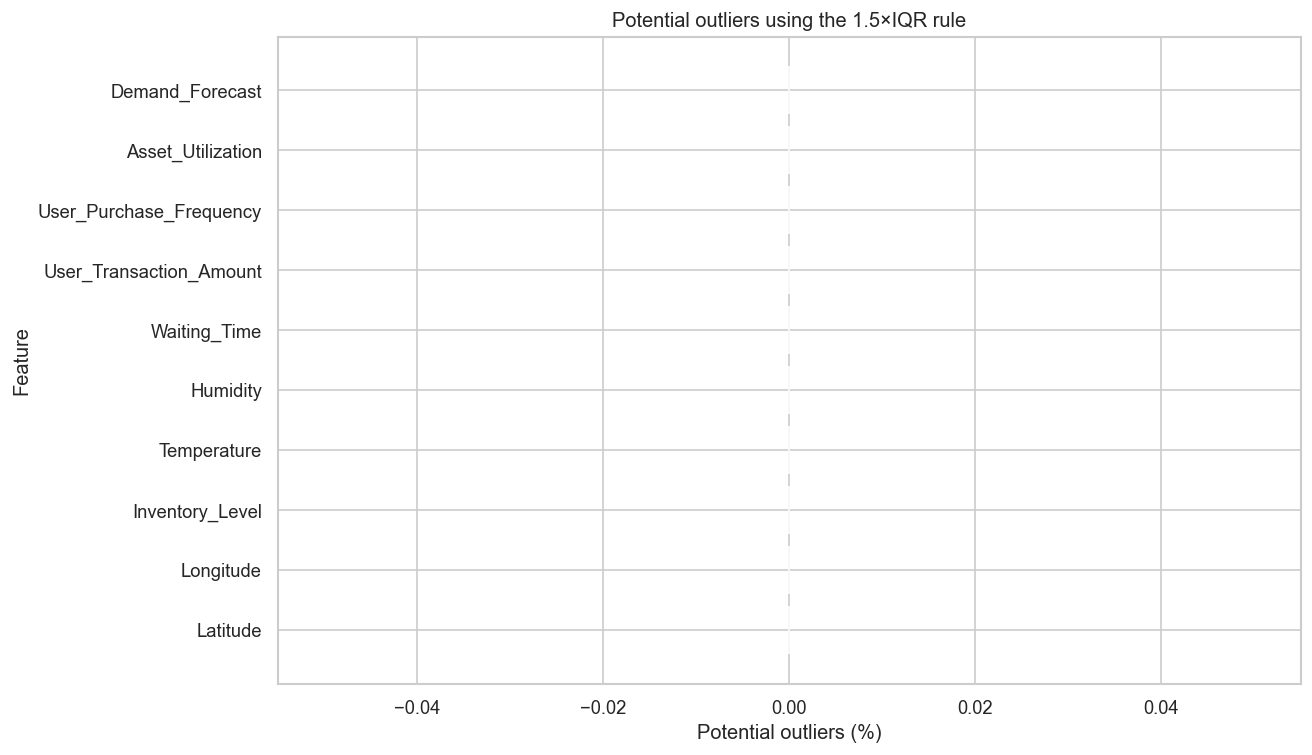

In [18]:
plot_out = outlier_table.sort_values("Outlier_%")

plt.figure(figsize=(11, 7))
plt.barh(plot_out["Feature"], plot_out["Outlier_%"])
plt.xlabel("Potential outliers (%)")
plt.ylabel("Feature")
plt.title("Potential outliers using the 1.5×IQR rule")
show_save("11_iqr_outlier_rates")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/12_operational_outlier_diagnostics.png


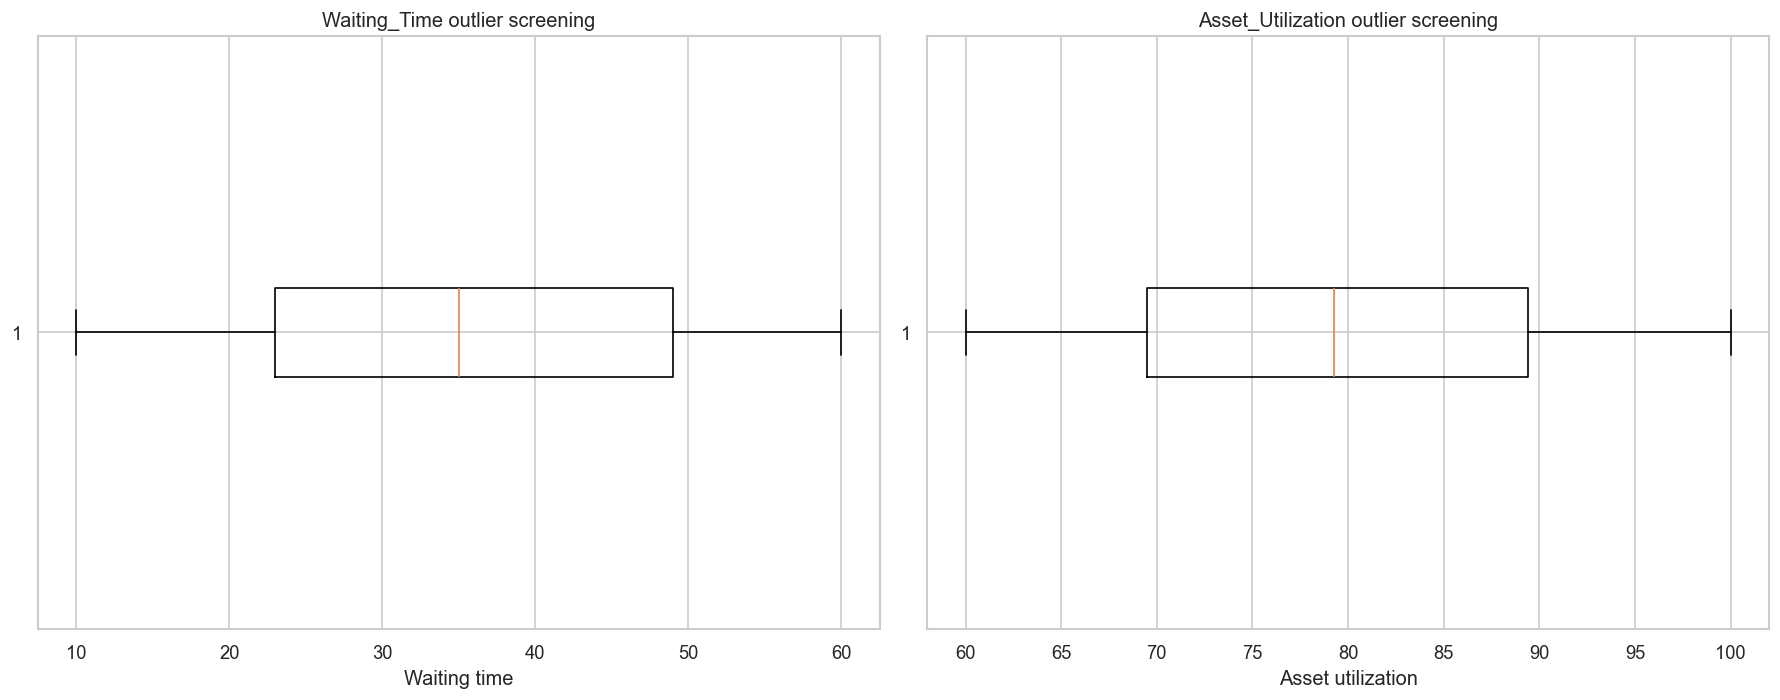

In [19]:
# Scatter-style diagnostic for the two operational variables most likely to show extremes
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].boxplot(df["Waiting_Time"], vert=False)
axes[0].set_title("Waiting_Time outlier screening")
axes[0].set_xlabel("Waiting time")

axes[1].boxplot(df["Asset_Utilization"], vert=False)
axes[1].set_title("Asset_Utilization outlier screening")
axes[1].set_xlabel("Asset utilization")

plt.tight_layout()
show_save("12_operational_outlier_diagnostics")


# Part D — Understand relationships among variables

## 10. Correlation analysis

Pearson correlation is used for numerical variables as a descriptive measure of linear association. Correlation does not establish causality and does not capture all nonlinear relationships.


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/13_correlation_heatmap.png


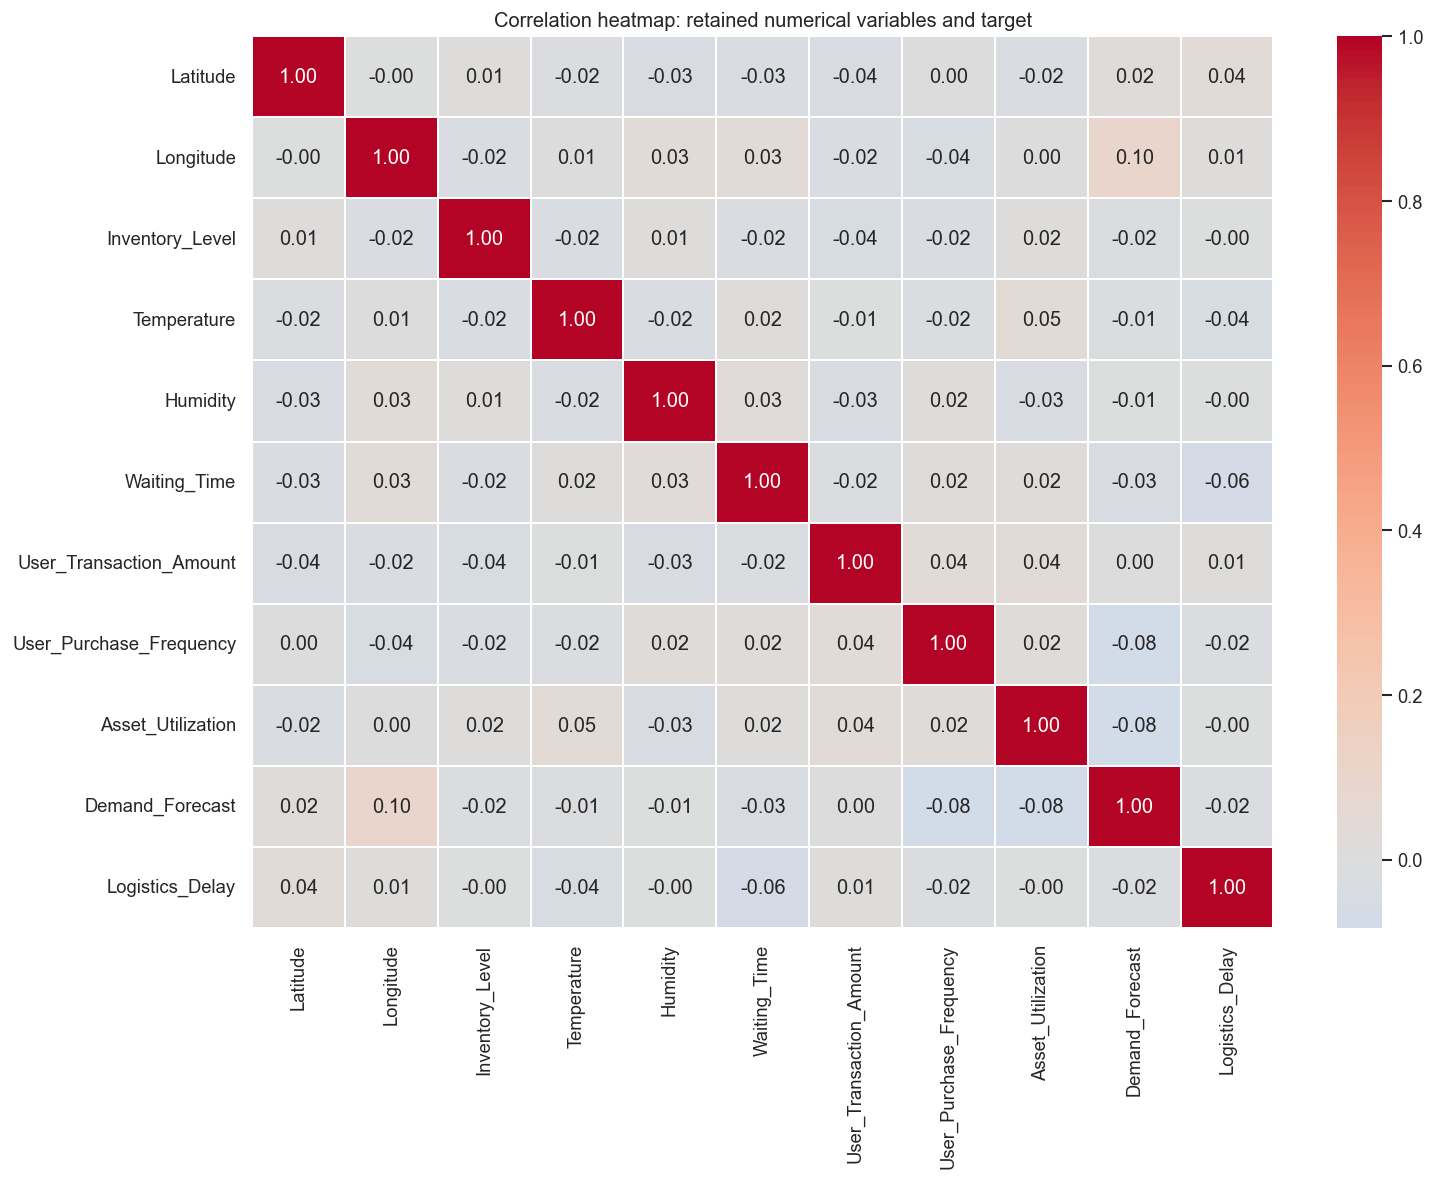

In [20]:
corr_cols = numeric_predictors + [TARGET]
corr = df[corr_cols].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", center=0, cmap="coolwarm", linewidths=0.2)
plt.title("Correlation heatmap: retained numerical variables and target")
plt.tight_layout()
show_save("13_correlation_heatmap")


In [21]:
# Strongest numerical associations with the target
target_corr = corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)
display(target_corr.to_frame("Pearson_r").round(3))

# Strongest feature-feature relationships
pair_corr = (
    corr.drop(index=TARGET, columns=TARGET)
        .where(np.triu(np.ones((len(numeric_predictors), len(numeric_predictors))), k=1).astype(bool))
        .stack()
        .reset_index()
)
pair_corr.columns = ["Feature_1", "Feature_2", "Pearson_r"]
pair_corr["Abs_r"] = pair_corr["Pearson_r"].abs()
display(pair_corr.sort_values("Abs_r", ascending=False).head(15).round(3))


,Pearson_r
Waiting_Time,-0.063
Latitude,0.040
Temperature,-0.038
Demand_Forecast,-0.019
User_Purchase_Frequency,-0.017
User_Transaction_Amount,0.014
Longitude,0.012
Inventory_Level,-0.003
Asset_Utilization,-0.003
Humidity,-0.001


,Feature_1,Feature_2,Pearson_r,Abs_r
16,Longitude,Demand_Forecast,0.098,0.098
43,User_Purchase_Frequency,Demand_Forecast,-0.083,0.083
44,Asset_Utilization,Demand_Forecast,-0.078,0.078
28,Temperature,Asset_Utilization,0.046,0.046
40,User_Transaction_Amount,Asset_Utilization,0.039,0.039
39,User_Transaction_Amount,User_Purchase_Frequency,0.038,0.038
14,Longitude,User_Purchase_Frequency,-0.037,0.037
20,Inventory_Level,User_Transaction_Amount,-0.037,0.037
5,Latitude,User_Transaction_Amount,-0.035,0.035
31,Humidity,User_Transaction_Amount,-0.035,0.035


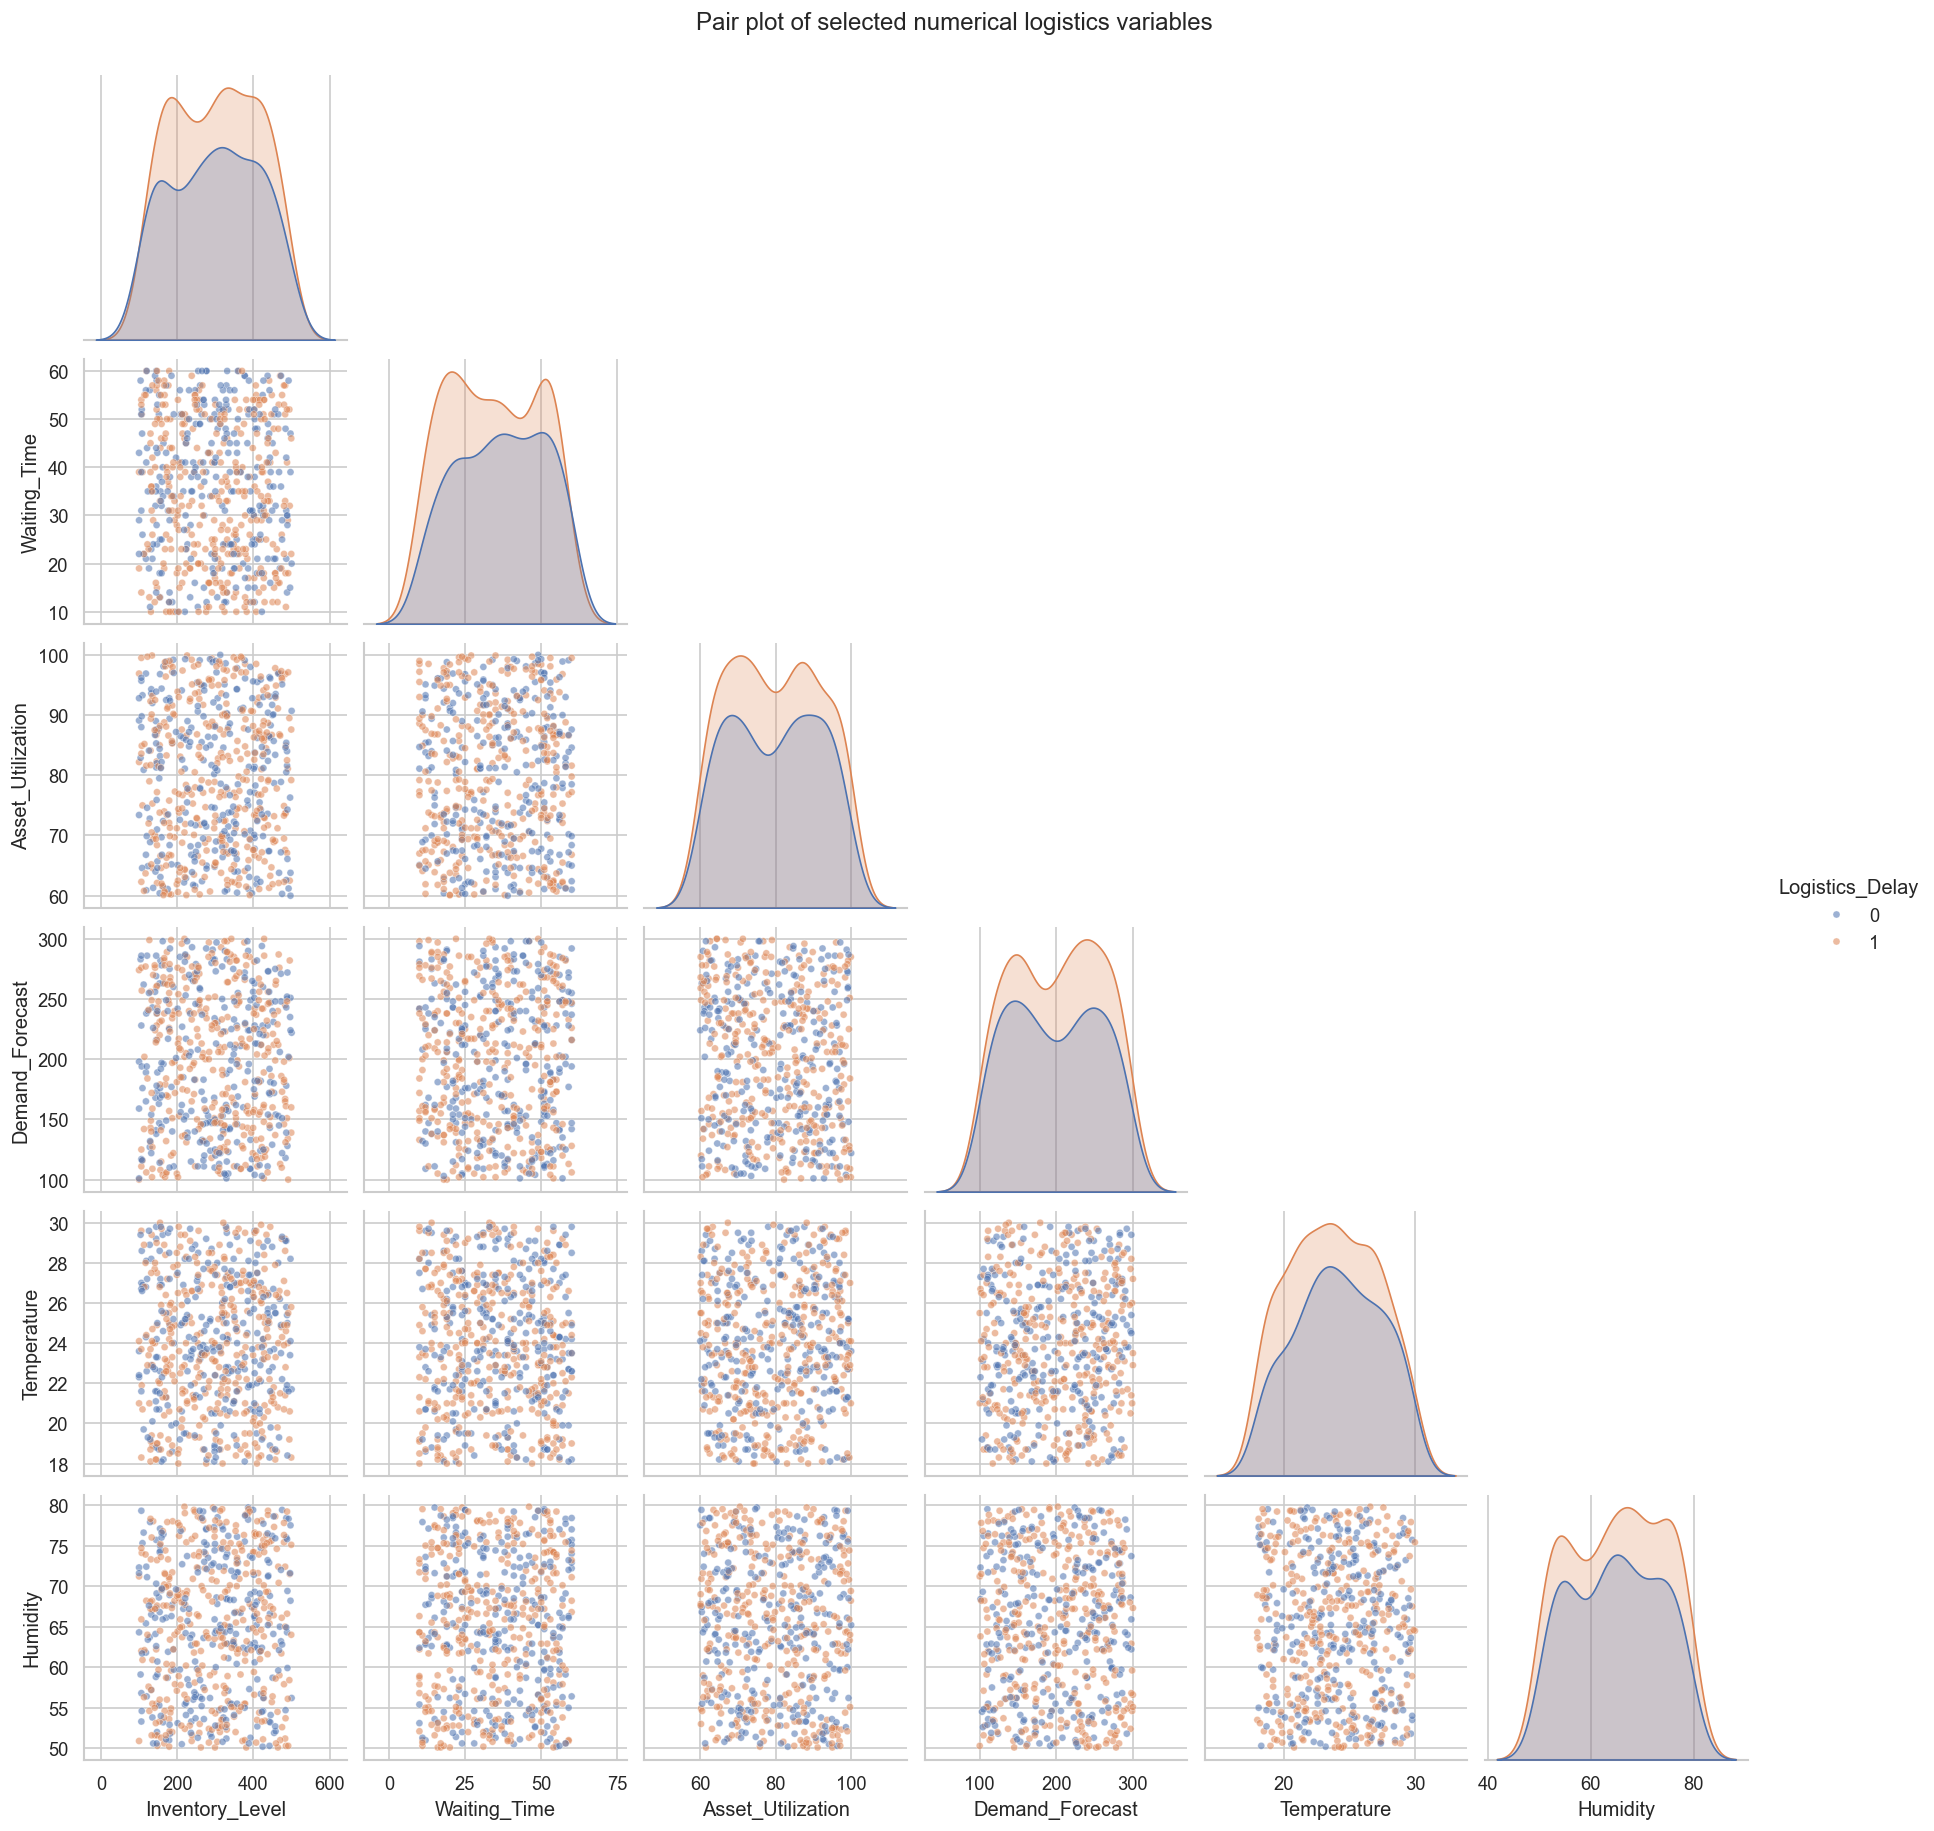

Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/14_pairplot_selected_variables.png


In [22]:
# Pair plot using the most operationally interpretable numerical variables
pair_cols = [
    "Inventory_Level", "Waiting_Time", "Asset_Utilization",
    "Demand_Forecast", "Temperature", "Humidity"
]
pair_sample = df[pair_cols + [TARGET]].sample(min(600, len(df)), random_state=42)

g = sns.pairplot(
    pair_sample,
    vars=pair_cols,
    hue=TARGET,
    corner=True,
    plot_kws={"alpha": 0.55, "s": 18}
)
g.fig.suptitle("Pair plot of selected numerical logistics variables", y=1.02)
g.fig.savefig(PLOT_DIR / "14_pairplot_selected_variables.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {PLOT_DIR / '14_pairplot_selected_variables.png'}")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/15_parallel_coordinates.png


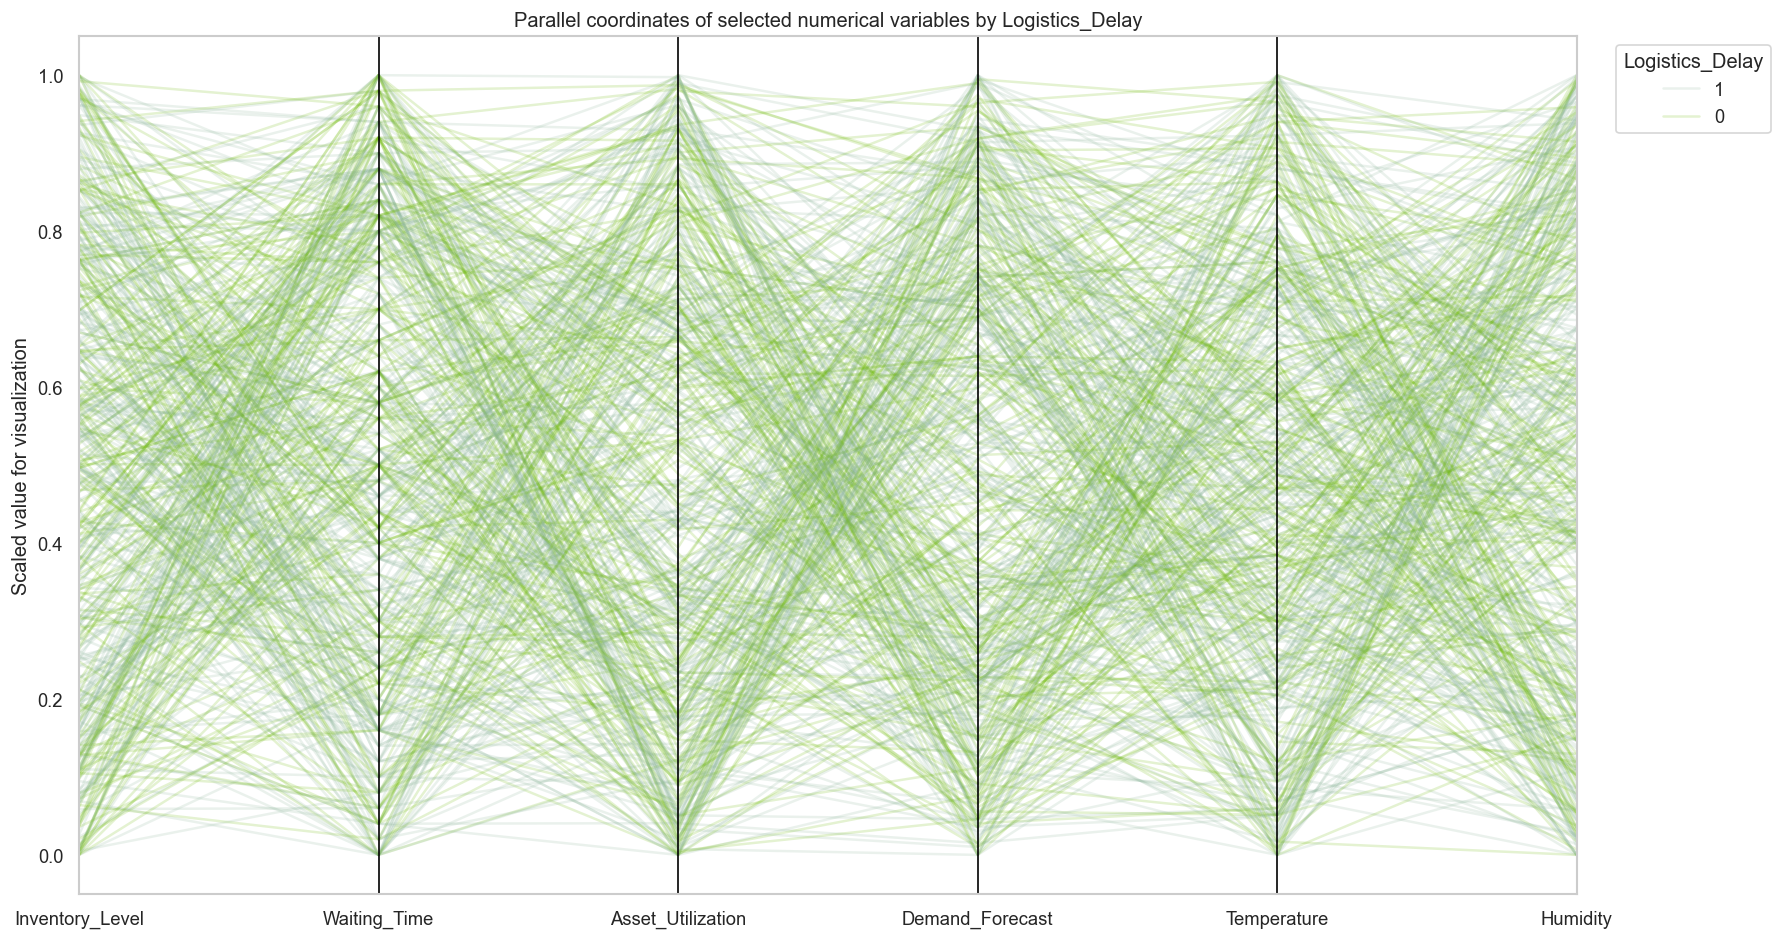

In [23]:
# Parallel coordinates — normalized only for visualization
pc_cols = [
    "Inventory_Level", "Waiting_Time", "Asset_Utilization",
    "Demand_Forecast", "Temperature", "Humidity"
]
pc = df[pc_cols + [TARGET]].sample(min(500, len(df)), random_state=42).copy()

for col in pc_cols:
    lo, hi = df[col].quantile(0.01), df[col].quantile(0.99)
    pc[col] = pc[col].clip(lo, hi)
    pc[col] = (pc[col] - pc[col].min()) / (pc[col].max() - pc[col].min())

plt.figure(figsize=(15, 8))
parallel_coordinates(pc, TARGET, alpha=0.18)
plt.ylabel("Scaled value for visualization")
plt.title("Parallel coordinates of selected numerical variables by Logistics_Delay")
plt.legend(title=TARGET, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
show_save("15_parallel_coordinates")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/16_bubble_waiting_utilization_inventory.png


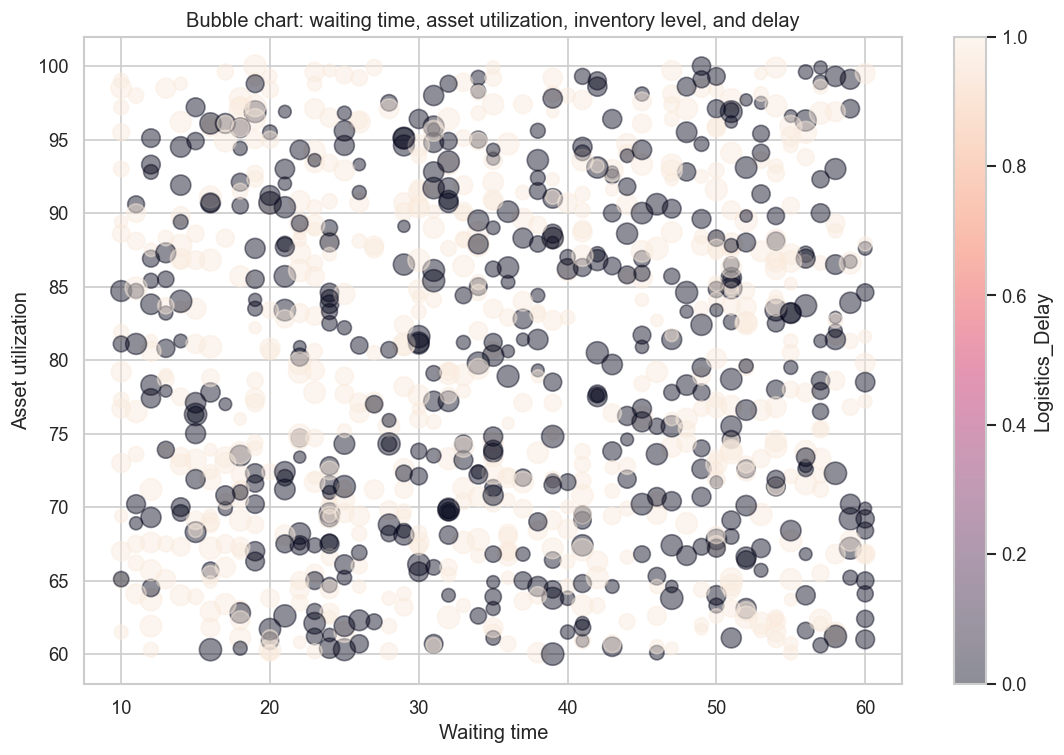

In [24]:
# Bubble chart: waiting time vs asset utilization
bubble = df[[
    "Waiting_Time", "Asset_Utilization",
    "Demand_Forecast", "Inventory_Level", TARGET
]].copy()

size = 20 + 160 * (bubble["Inventory_Level"] / bubble["Inventory_Level"].max())

plt.figure(figsize=(11, 7))
sc = plt.scatter(
    bubble["Waiting_Time"],
    bubble["Asset_Utilization"],
    s=size,
    c=bubble[TARGET],
    alpha=0.45
)
plt.colorbar(sc, label="Logistics_Delay")
plt.xlabel("Waiting time")
plt.ylabel("Asset utilization")
plt.title("Bubble chart: waiting time, asset utilization, inventory level, and delay")
show_save("16_bubble_waiting_utilization_inventory")


## 11. Target relationships beyond simple correlation

Because `Logistics_Delay` is binary, group-level delay rates can be more informative than Pearson correlation alone. The next analyses compare delay rates across bins of operational variables.

These plots are descriptive: they show differences in observed rates, not causal effects.


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/17_delay_rate_by_numerical_quartiles.png


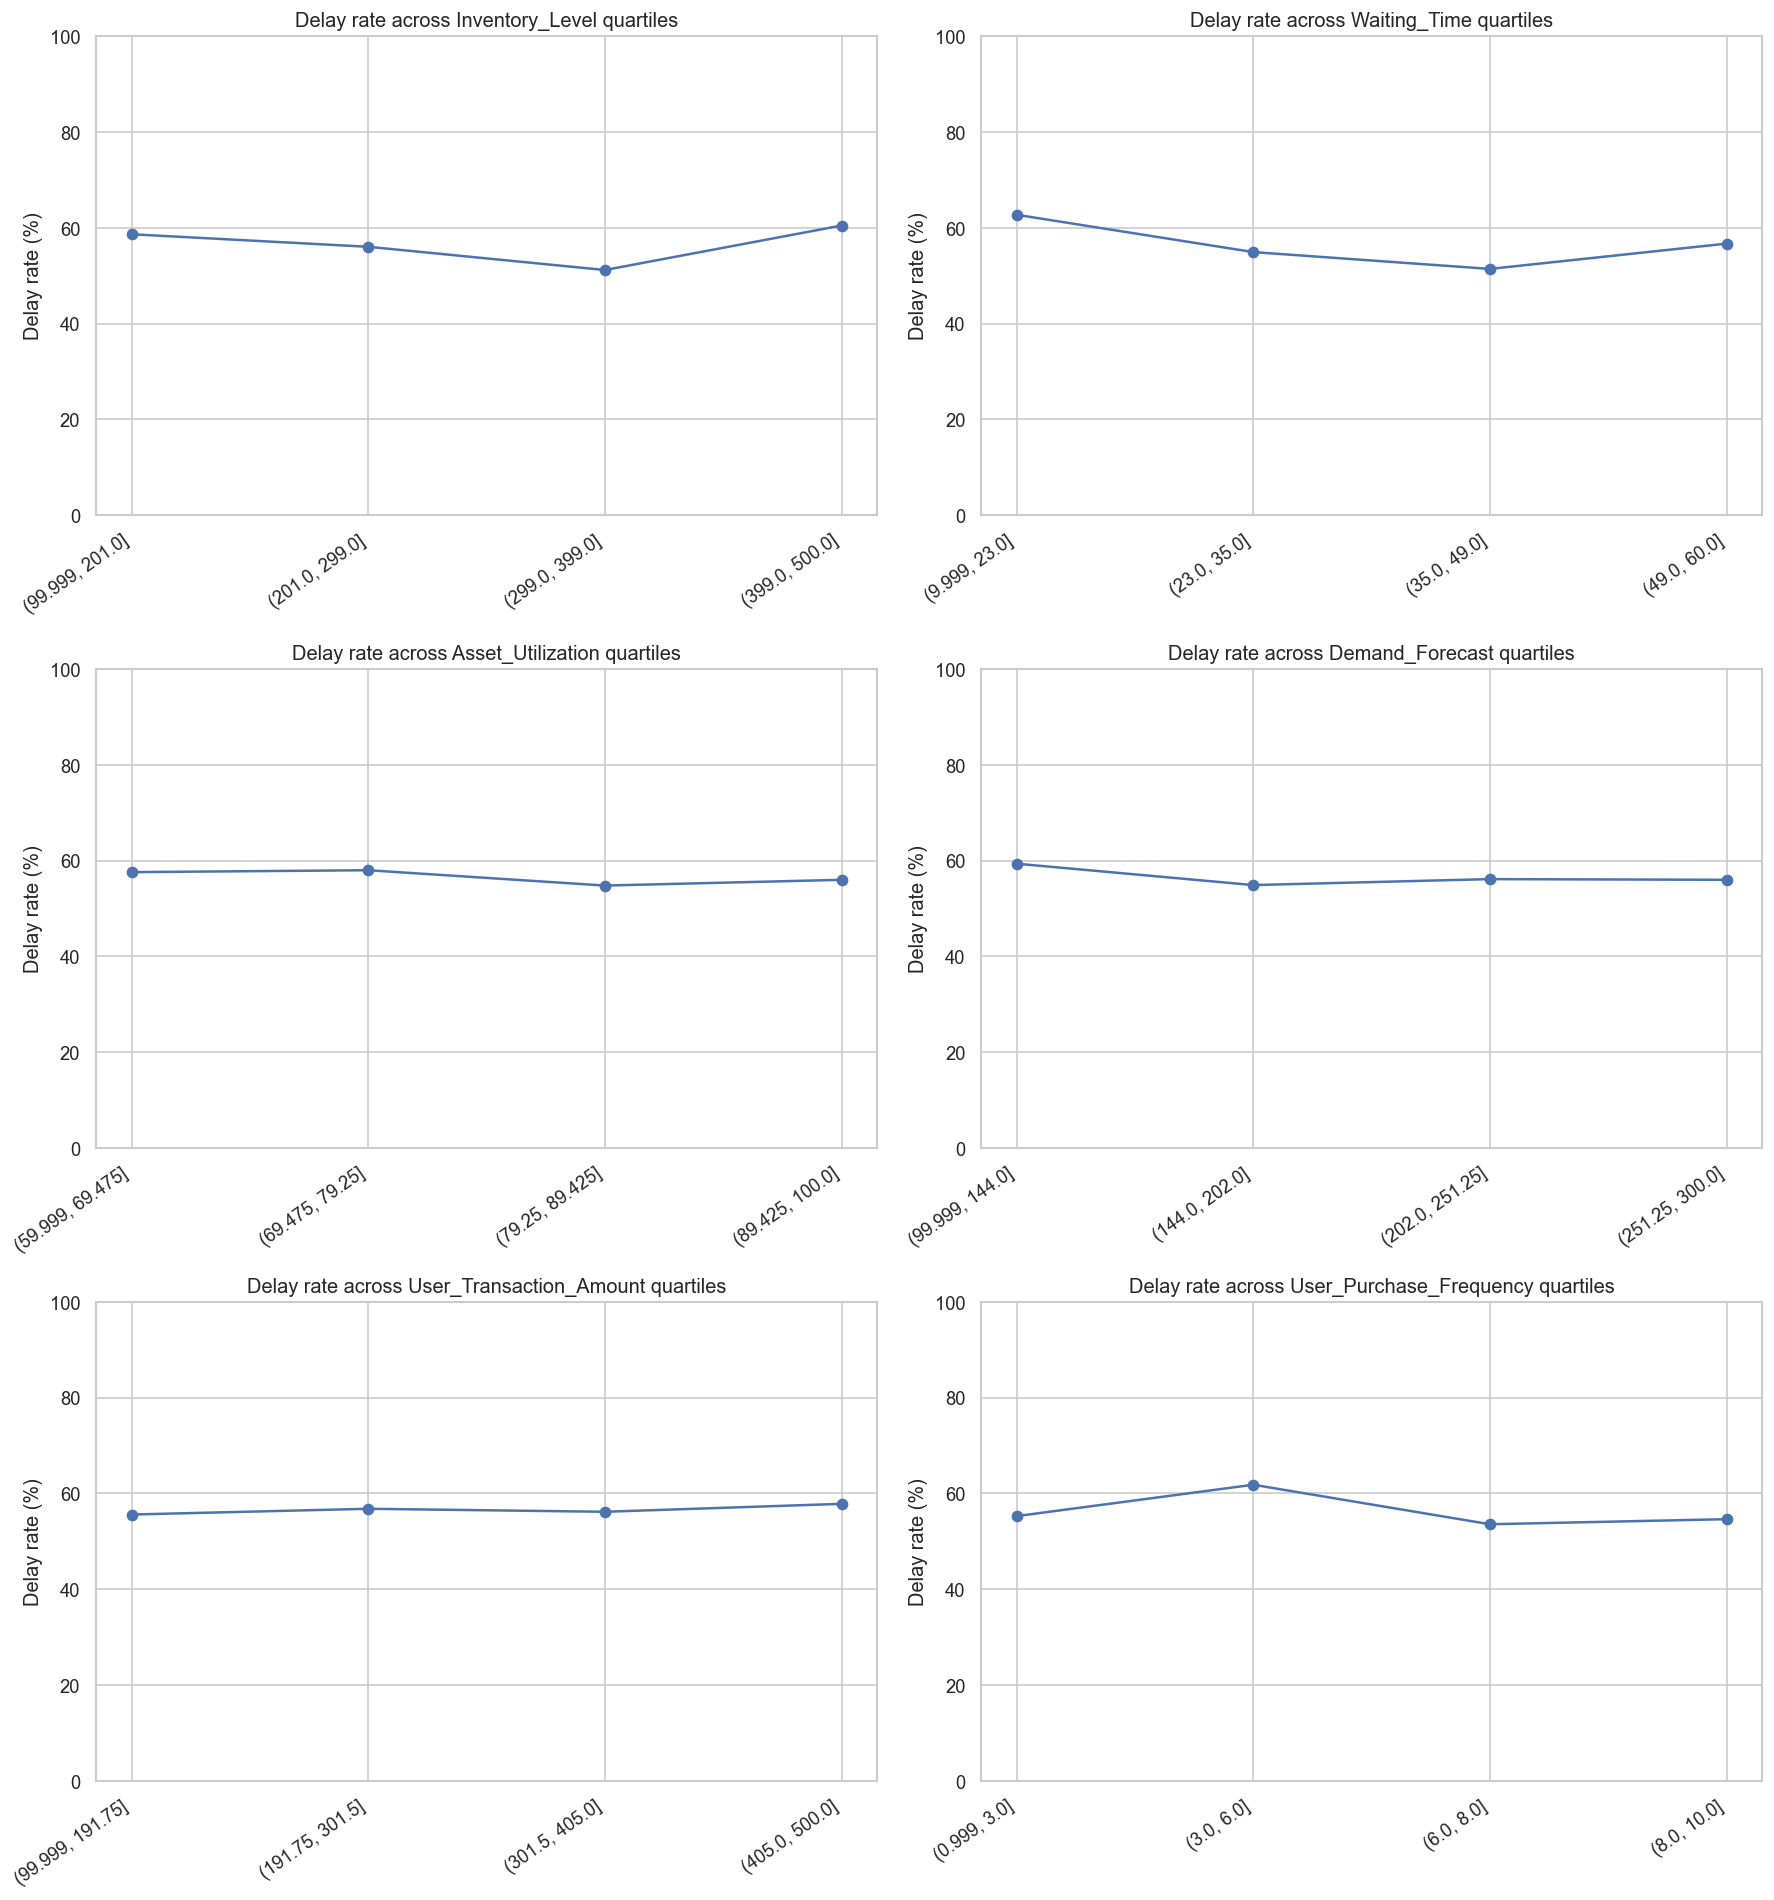

In [25]:
def delay_rate_by_quantile(col, q=4):
    bins = pd.qcut(df[col], q=q, duplicates="drop")
    result = df.groupby(bins, observed=True)[TARGET].agg(["mean", "count"])
    result["delay_rate_pct"] = result["mean"] * 100
    return result

rate_cols = [
    "Inventory_Level", "Waiting_Time",
    "Asset_Utilization", "Demand_Forecast",
    "User_Transaction_Amount", "User_Purchase_Frequency"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 16))
for ax, col in zip(axes.ravel(), rate_cols):
    r = delay_rate_by_quantile(col)
    ax.plot(range(len(r)), r["delay_rate_pct"], marker="o")
    ax.set_xticks(range(len(r)))
    ax.set_xticklabels([str(x) for x in r.index], rotation=35, ha="right")
    ax.set_ylabel("Delay rate (%)")
    ax.set_title(f"Delay rate across {col} quartiles")
    ax.set_ylim(0, 100)

plt.tight_layout()
show_save("17_delay_rate_by_numerical_quartiles")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/18_delay_rate_waiting_time_bands.png


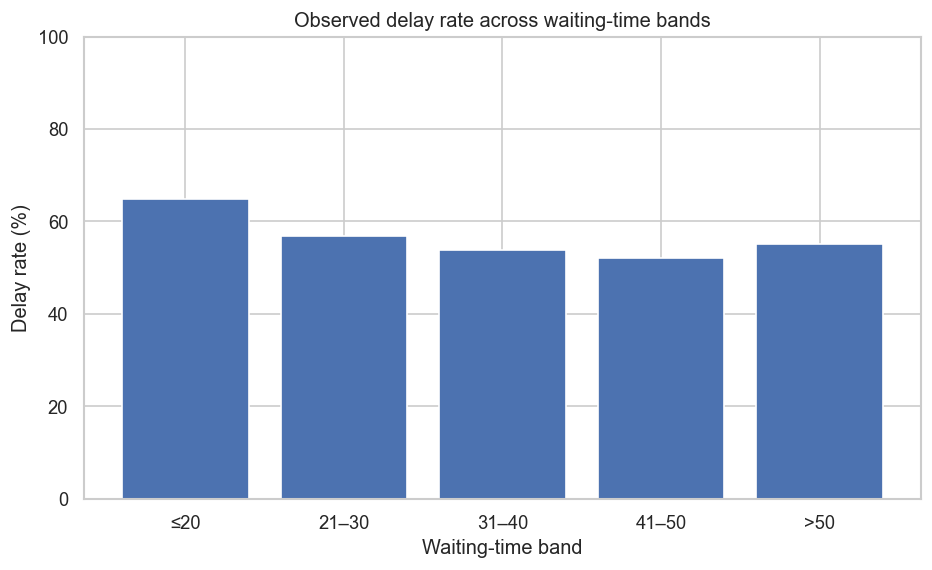

In [26]:
# Waiting-time bands
df["Waiting_Time_Band"] = pd.cut(
    df["Waiting_Time"],
    bins=[-np.inf, 20, 30, 40, 50, np.inf],
    labels=["≤20", "21–30", "31–40", "41–50", ">50"]
)

waiting_rate = df.groupby("Waiting_Time_Band", observed=True)[TARGET].mean() * 100

plt.figure(figsize=(9, 5))
plt.bar(waiting_rate.index.astype(str), waiting_rate.values)
plt.ylabel("Delay rate (%)")
plt.xlabel("Waiting-time band")
plt.title("Observed delay rate across waiting-time bands")
plt.ylim(0, 100)
show_save("18_delay_rate_waiting_time_bands")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/19_inventory_vs_demand_delay.png


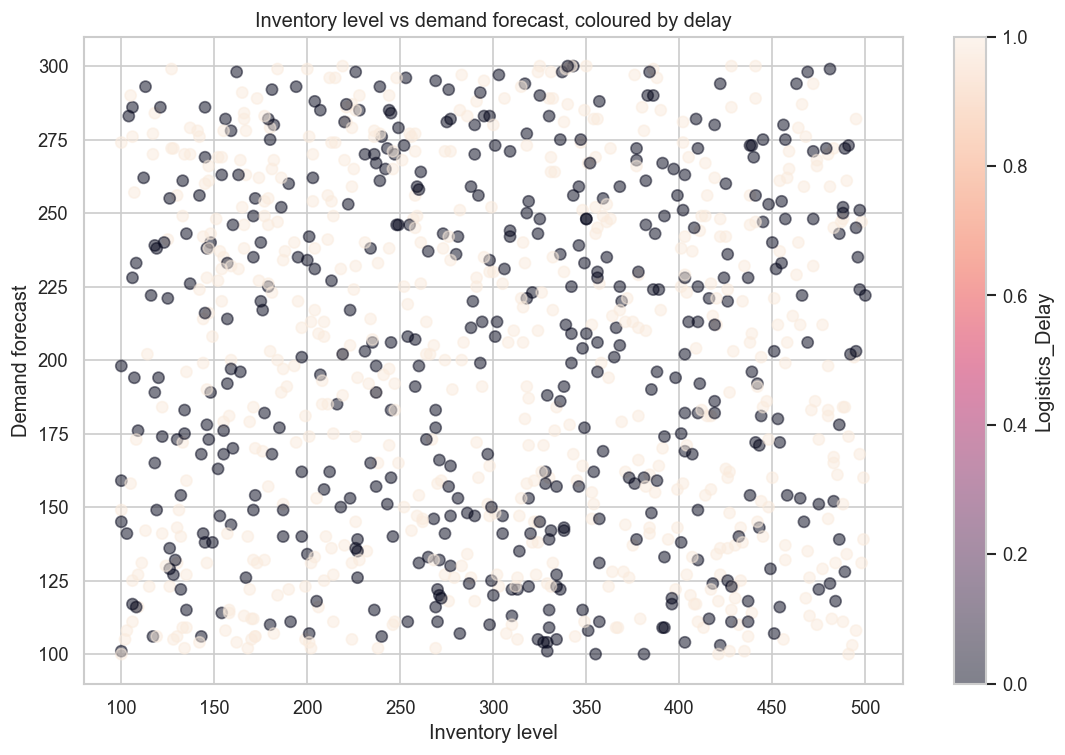

In [27]:
# Inventory vs demand: operational pressure proxy
plt.figure(figsize=(11, 7))
sc = plt.scatter(
    df["Inventory_Level"],
    df["Demand_Forecast"],
    c=df[TARGET],
    alpha=0.5,
    s=45
)
plt.colorbar(sc, label="Logistics_Delay")
plt.xlabel("Inventory level")
plt.ylabel("Demand forecast")
plt.title("Inventory level vs demand forecast, coloured by delay")
show_save("19_inventory_vs_demand_delay")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/20_geographic_distribution_delay.png


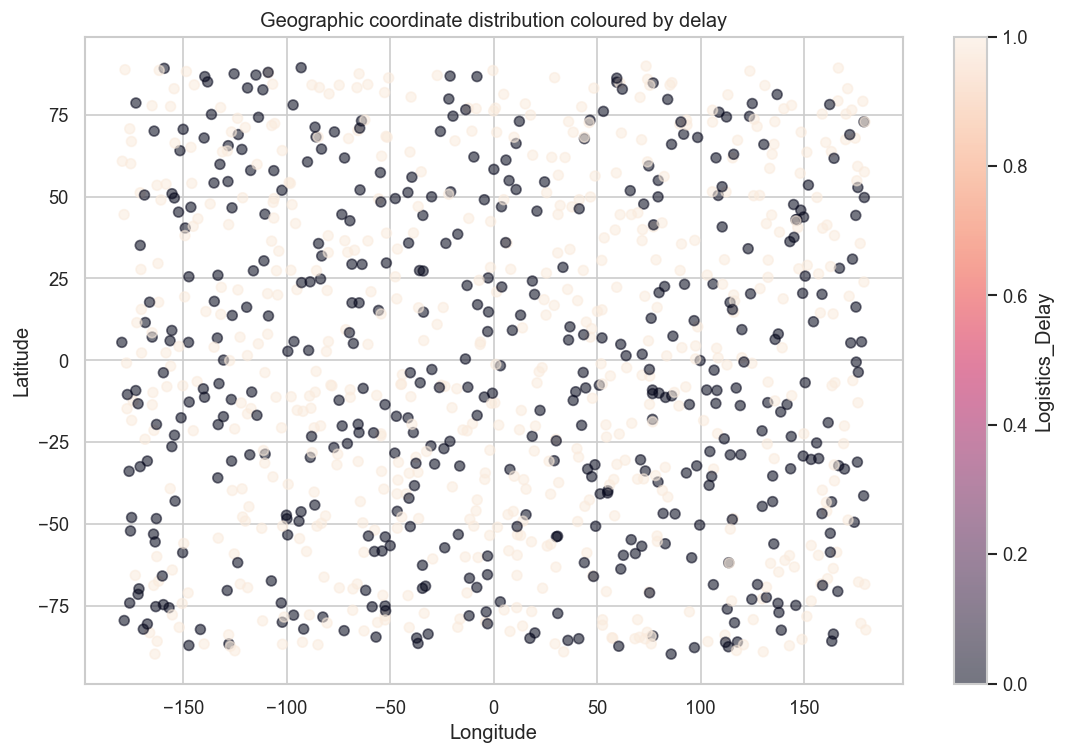

In [28]:
# Geographic scatter: descriptive only
plt.figure(figsize=(11, 7))
sc = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df[TARGET],
    alpha=0.55,
    s=35
)
plt.colorbar(sc, label="Logistics_Delay")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic coordinate distribution coloured by delay")
show_save("20_geographic_distribution_delay")


### Geographic interpretation caution

The supplied file contains latitude and longitude values spanning broad global ranges. The CSV does not provide a route network, country/region labels, projection metadata, or geographic source. Therefore, the plot above is treated only as a **coordinate-distribution visualization**, not as a validated road-network or route map.


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/21_monthly_delay_rate.png


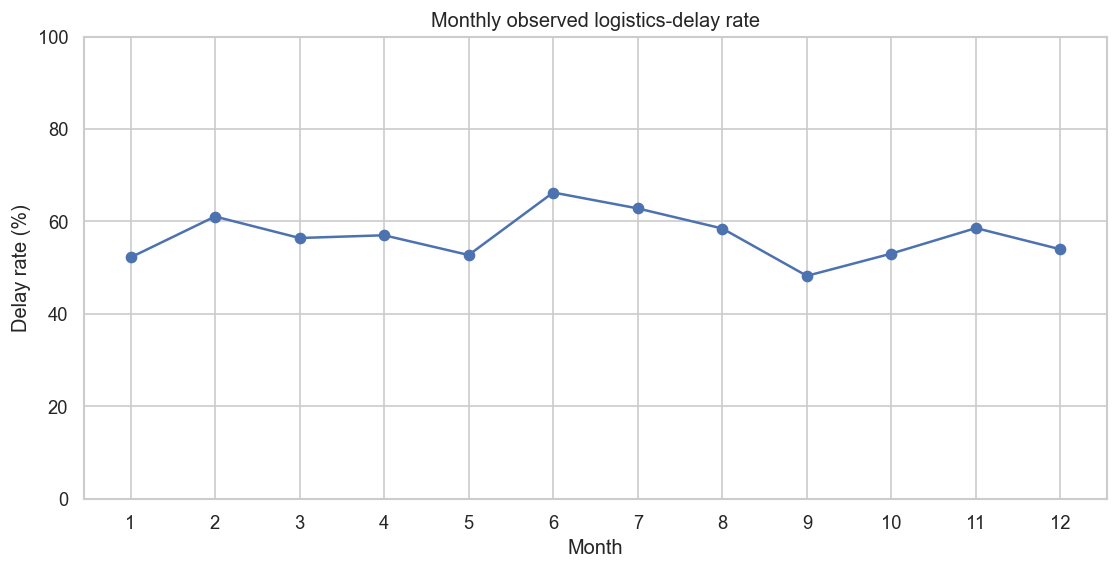

In [29]:
# Temporal features derived from Timestamp
df["Month"] = df["Timestamp_parsed"].dt.month
df["Month_Name"] = df["Timestamp_parsed"].dt.strftime("%b")
df["Day_of_Week"] = df["Timestamp_parsed"].dt.day_name()
df["Hour"] = df["Timestamp_parsed"].dt.hour

month_order = list(range(1, 13))
monthly_rate = df.groupby("Month")[TARGET].mean() * 100

plt.figure(figsize=(11, 5))
plt.plot(monthly_rate.index, monthly_rate.values, marker="o")
plt.xticks(month_order)
plt.xlabel("Month")
plt.ylabel("Delay rate (%)")
plt.title("Monthly observed logistics-delay rate")
plt.ylim(0, 100)
show_save("21_monthly_delay_rate")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/22_hourly_delay_rate.png


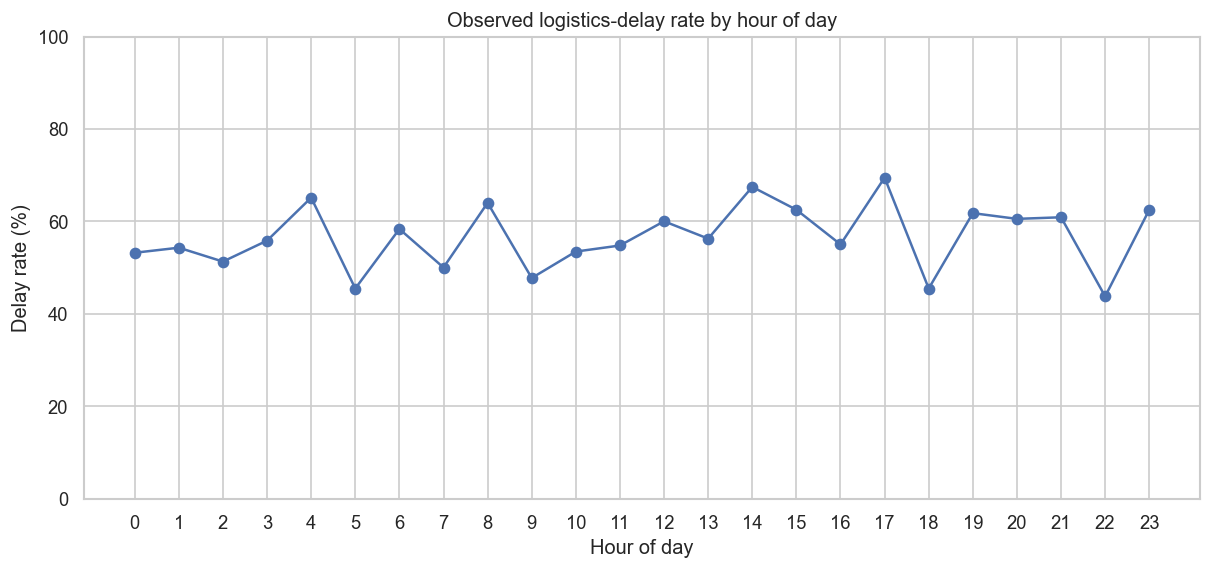

In [30]:
hourly_rate = df.groupby("Hour")[TARGET].mean() * 100

plt.figure(figsize=(12, 5))
plt.plot(hourly_rate.index, hourly_rate.values, marker="o")
plt.xticks(range(24))
plt.xlabel("Hour of day")
plt.ylabel("Delay rate (%)")
plt.title("Observed logistics-delay rate by hour of day")
plt.ylim(0, 100)
show_save("22_hourly_delay_rate")


Saved: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-3/23_weekday_delay_rate.png


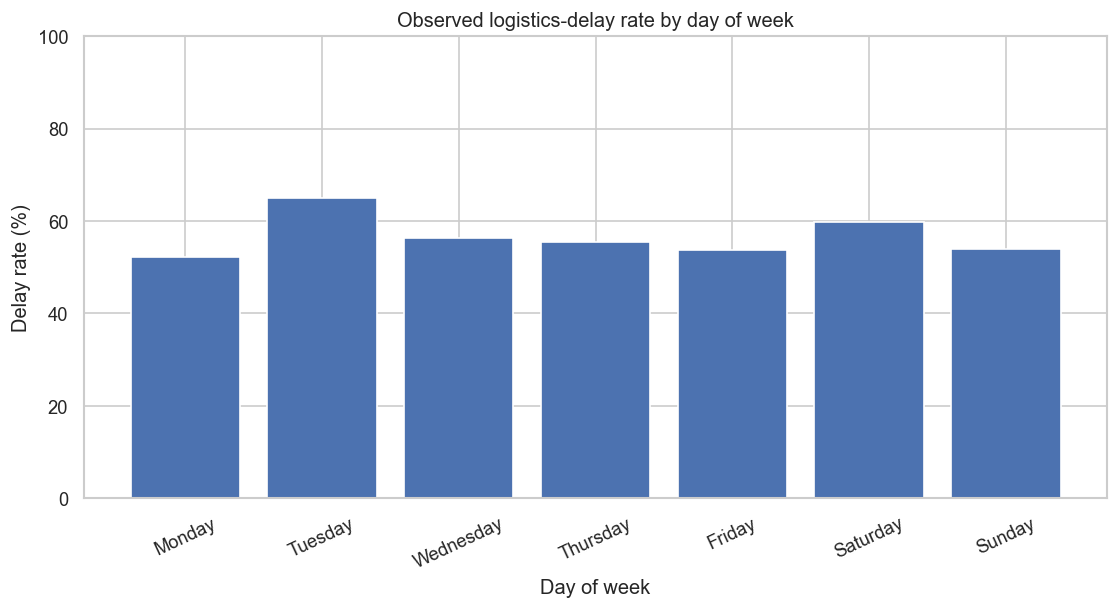

In [31]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_rate = df.groupby("Day_of_Week")[TARGET].mean().reindex(weekday_order) * 100

plt.figure(figsize=(11, 5))
plt.bar(weekday_rate.index, weekday_rate.values)
plt.xticks(rotation=25)
plt.ylabel("Delay rate (%)")
plt.xlabel("Day of week")
plt.title("Observed logistics-delay rate by day of week")
plt.ylim(0, 100)
show_save("23_weekday_delay_rate")


# Part E — Leakage audit

## 12. Why `Shipment_Status` and `Logistics_Delay_Reason` are excluded

The project instruction specifically warns about target revelation. The supplied data confirm why this is important.

`Shipment_Status` contains values such as `Delayed`, `Delivered`, and `In Transit`. A status recorded after or because of a delay can directly expose the target.

`Logistics_Delay_Reason` contains categories such as `Weather`, `Traffic`, and `Mechanical Failure`. A recorded delay reason is inherently tied to the occurrence of a delay and is therefore not an appropriate predictor when the task is to predict whether a delay occurs.

These variables are shown below only to document the leakage audit. They are **not used in the retained feature set**.


In [32]:
for col in LEAKAGE_COLS:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False).to_frame("count"))

# Demonstrate target association for audit only — NOT for modeling
for col in LEAKAGE_COLS:
    audit = pd.crosstab(df[col].fillna("Missing"), df[TARGET], normalize="index") * 100
    print(f"Target distribution by {col} (leakage audit only):")
    display(audit.round(2))



--- Shipment_Status ---


,count
Shipment_Status,
Delayed,350
Delivered,338
In Transit,312



--- Logistics_Delay_Reason ---


,count
Logistics_Delay_Reason,
Weather,267
NaN,263
Traffic,236
Mechanical Failure,234


Target distribution by Shipment_Status (leakage audit only):


Logistics_Delay,0,1
Shipment_Status,,
Delayed,0.00,100.00
Delivered,65.09,34.91
In Transit,68.59,31.41


Target distribution by Logistics_Delay_Reason (leakage audit only):


Logistics_Delay,0,1
Logistics_Delay_Reason,,
Mechanical Failure,43.16,56.84
Missing,44.11,55.89
Traffic,42.80,57.20
Weather,43.45,56.55


### Leakage decision

| Column | Decision | Reason |
|---|---|---|
| `Shipment_Status` | **Exclude** | Describes shipment outcome/status and can reveal an already-realized delay. |
| `Logistics_Delay_Reason` | **Exclude** | Explicitly records the reason for the target event and is therefore outcome-derived. |
| `Logistics_Delay` | **Target** | Outcome to predict. |

This is a **feature-availability decision**, not a claim that these columns are unimportant operationally. They may be useful for retrospective diagnosis, but they should not be used as predictors when the goal is to predict the delay outcome without target leakage.


# Part F — Statistical relationship checks

## 13. Group differences and effect-size-oriented summaries

For categorical predictors, contingency tables and observed delay rates are used. For numerical predictors, group means/medians and distribution plots are used.

The goal is not to declare causality but to identify variables that deserve deeper investigation in the subsequent modeling stage.


In [33]:
# Numerical variables: descriptive comparison by target
group_summary = df.groupby(TARGET)[numeric_predictors].agg(["mean", "median"])
display(group_summary.round(3))


Latitude        Longitude        Inventory_Level         \
                    mean median      mean median            mean median   
Logistics_Delay                                                           
0                 -3.712 -8.540    -0.575 -3.328         298.348  301.5   
1                  0.444 -1.353     1.919  4.960         297.583  296.0   

                Temperature        Humidity        Waiting_Time         \
                       mean median     mean median         mean median   
Logistics_Delay                                                          
0                    24.038   24.0   65.047  65.10       36.104   36.0   
1                    23.783   23.8   65.038  65.35       34.263   34.0   

                User_Transaction_Amount        User_Purchase_Frequency         \
                                   mean median                    mean median   
Logistics_Delay                                                                 
0                               297.226  299.5                   5.571    6.0   
1                               300.458  304.0                   5.468    5.5   

                Asset_Utilization        Demand_Forecast         
                             mean median            mean median  
Logistics_Delay                                                  
0                          79.641   80.0         200.558  202.5  
1                          79.567   79.0         198.307  200.5

In [34]:
# Categorical predictors: counts and delay rates
for col in categorical_predictors:
    summary = df.groupby(col)[TARGET].agg(["count", "mean"])
    summary["delay_rate_pct"] = summary["mean"] * 100
    print(f"\n{col}")
    display(summary.round(3))



Asset_ID


,count,mean,delay_rate_pct
Asset_ID,,,
Truck_1,89,0.517,51.685
Truck_10,105,0.648,64.762
Truck_2,105,0.533,53.333
Truck_3,93,0.624,62.366
Truck_4,107,0.589,58.879
Truck_5,93,0.495,49.462
Truck_6,103,0.524,52.427
Truck_7,102,0.588,58.824
Truck_8,109,0.569,56.881



Traffic_Status


,count,mean,delay_rate_pct
Traffic_Status,,,
Clear,328,0.351,35.061
Detour,345,0.359,35.942
Heavy,327,1.000,100.000


In [35]:
# Mann–Whitney U screening for numerical variables.
# This is a non-parametric group-comparison diagnostic, not a causal test.
mw_records = []

for col in numeric_predictors:
    g0 = df.loc[df[TARGET] == 0, col].dropna()
    g1 = df.loc[df[TARGET] == 1, col].dropna()
    stat, p = stats.mannwhitneyu(g0, g1, alternative="two-sided")
    mw_records.append({
        "Feature": col,
        "Median_delay_0": g0.median(),
        "Median_delay_1": g1.median(),
        "U_statistic": stat,
        "p_value": p
    })

mw_table = pd.DataFrame(mw_records).sort_values("p_value")
display(mw_table.round(5))


,Feature,Median_delay_0,Median_delay_1,U_statistic,p_value
5,Waiting_Time,36.00000,34.0000,131811.0,0.04702
0,Latitude,-8.53975,-1.3529,117289.0,0.22163
3,Temperature,24.00000,23.8000,128234.0,0.23188
9,Demand_Forecast,202.50000,200.5000,125594.0,0.54036
7,User_Purchase_Frequency,6.00000,5.5000,125298.0,0.58254
6,User_Transaction_Amount,299.50000,304.0000,120786.0,0.65295
1,Longitude,-3.32800,4.9597,121143.0,0.71079
2,Inventory_Level,301.50000,296.0000,123350.0,0.90723
8,Asset_Utilization,80.00000,79.0000,123157.5,0.94101
4,Humidity,65.10000,65.3500,122938.5,0.97956


### Statistical-test caution

The Mann–Whitney U results are exploratory screening statistics. A small p-value does not establish operational causality, and multiple comparisons can inflate the chance of apparently significant findings. The results should therefore be interpreted together with effect size, distributions, domain logic, and later validation rather than used as automatic feature-selection rules.


# Part G — Brainstorming

## 14. Evidence-based findings, hypotheses, and questions

The following brainstorming section deliberately separates:

- **Finding:** what is directly observed in the supplied data;
- **Hypothesis:** a testable interpretation that could explain or predict a pattern;
- **Question:** something that should be investigated in later modeling or with domain information.

Every point cross-references an EDA figure/table.


In [36]:
# Generate a compact evidence table for use in the report
strongest_target_corr_feature = target_corr.index[0]
strongest_target_corr_value = target_corr.iloc[0]

highest_asset_rate = asset_delay_rate.index[0]
lowest_asset_rate = asset_delay_rate.index[-1]

evidence = pd.DataFrame([
    {
        "Type": "Finding",
        "Statement": f"The target has {target_counts.get(0,0):,} non-delay and {target_counts.get(1,0):,} delay observations.",
        "Evidence": "Figures 1–2"
    },
    {
        "Type": "Finding",
        "Statement": f"The strongest absolute Pearson correlation between a retained numerical variable and Logistics_Delay is {strongest_target_corr_feature} (r={strongest_target_corr_value:.3f}).",
        "Evidence": "Figure 13"
    },
    {
        "Type": "Finding",
        "Statement": f"Among assets, {highest_asset_rate} has the highest observed delay rate, while {lowest_asset_rate} has the lowest.",
        "Evidence": "Figure 10"
    },
    {
        "Type": "Finding",
        "Statement": f"Traffic_Status shows materially different observed delay rates across its categories.",
        "Evidence": "Figure 9"
    }
])

display(evidence)


,Type,Statement,Evidence
0,Finding,The target has 434 non-delay and 566 delay obs...,Figures 1–2
1,Finding,The strongest absolute Pearson correlation bet...,Figure 13
2,Finding,"Among assets, Truck_10 has the highest observe...",Figure 10
3,Finding,Traffic_Status shows materially different obse...,Figure 9


### Brainstorming point 1 — Traffic conditions are a primary candidate signal

**Finding:** The observed delay rate differs substantially across `Traffic_Status` categories (Figure 9). The supplied values include `Clear`, `Heavy`, and `Detour`.

**Hypothesis:** Traffic conditions may contain strong information about whether a logistics observation is delayed.

**Question:** Does `Traffic_Status` remain informative after controlling for waiting time, asset utilization, demand, time-of-day, and asset identity?

**Why it matters:** Traffic is operationally available before a shipment outcome is finalized, so it is conceptually aligned with a predictive use case.


### Brainstorming point 2 — Waiting time may act as an operational warning signal

**Finding:** `Waiting_Time` has a measurable distribution and its observed delay rate changes across waiting-time bands (Figures 4–6 and Figure 18).

**Hypothesis:** Longer waiting time may be associated with a higher probability of delay because it reflects accumulated operational friction.

**Question:** Is the relationship approximately monotonic, or are there threshold effects where delay risk changes sharply?

**Follow-up:** Later modeling could compare a linear effect with nonlinear tree-based or spline-style representations.


### Brainstorming point 3 — Asset-level differences should be investigated carefully

**Finding:** Observed delay rates vary across `Asset_ID` (Figure 10).

**Hypothesis:** Different assets may operate under different utilization patterns or routes, producing different observed delay rates.

**Question:** Are asset-level differences still present after accounting for traffic, demand, waiting time, and temporal variables?

**Caution:** `Asset_ID` is an identifier rather than a physical measurement. A model may memorize historical asset behavior without generalizing to a new asset.


### Brainstorming point 4 — Inventory and demand should be examined jointly

**Finding:** `Inventory_Level` and `Demand_Forecast` represent two different sides of supply-chain pressure and are visualized jointly in Figure 19.

**Hypothesis:** Delay patterns may differ when forecast demand is high relative to available inventory.

**Question:** Would a derived ratio or gap such as `Demand_Forecast - Inventory_Level` provide additional information, and would that relationship remain stable across assets and time?

**Important:** Such a feature would be engineered from retained predictors and would not use either excluded leakage column.


### Brainstorming point 5 — Asset utilization may interact with demand

**Finding:** `Asset_Utilization` spans a broad operational range and is examined against `Waiting_Time`, inventory, and demand in Figures 4–6, 16, and 19.

**Hypothesis:** High utilization combined with high demand may create conditions associated with greater delay risk.

**Question:** Does utilization have a simple linear relationship with delay, or is there a threshold beyond which the observed delay rate changes more rapidly?

**Follow-up:** Interaction terms or nonlinear models could be evaluated in the later modeling phase.


### Brainstorming point 6 — Environmental variables may have conditional rather than isolated effects

**Finding:** Temperature and humidity are present as structured measurements, and their distributions are shown in Figures 4–6.

**Hypothesis:** Environmental conditions may matter primarily under specific traffic, utilization, or demand regimes rather than as independent predictors.

**Question:** Do temperature/humidity effects differ when traffic is heavy or when waiting time is high?

**Follow-up:** Interaction plots and tree-based models could investigate conditional patterns.


### Brainstorming point 7 — Time may reveal operational regimes

**Finding:** The timestamps cover most of 2024, allowing month, hour, and day-of-week features to be derived. Figures 21–23 show observed delay rates over these temporal dimensions.

**Hypothesis:** Logistics delay risk may vary across operating periods because traffic, demand, and asset usage can have temporal patterns.

**Question:** Are temporal patterns still present after controlling for traffic and asset characteristics?

**Caution:** The timestamp is not itself evidence of causality; it is a context variable from which operational calendar features can be derived.


### Brainstorming point 8 — Geographic coordinates need validation before operational interpretation

**Finding:** The supplied latitude and longitude fields span broad geographic ranges (Figure 20).

**Hypothesis:** If these coordinates correspond to meaningful logistics locations, geographic position might capture route or regional effects.

**Question:** Do the coordinates represent actual operational locations, simulated coordinates, or another reference system?

**Reason for caution:** The supplied CSV contains no route geometry, location names, country labels, or coordinate-system documentation. Therefore, the current analysis treats them only as numerical geographic fields.


### Brainstorming point 9 — Leakage variables should be reserved for diagnosis

**Finding:** `Shipment_Status` and `Logistics_Delay_Reason` are directly related to the outcome and are explicitly excluded from the predictor set.

**Hypothesis:** Including them in a predictive model would produce an unrealistically easy task because the model could access information that may only become known after the delay event.

**Question:** At what exact point in the logistics process is each retained feature available? This should be confirmed before deployment-oriented modeling.

**Evidence:** Leakage-audit section and target cross-tabulations.


### Brainstorming point 10 — The dataset's provenance is itself a research question

**Finding:** The supplied CSV does not contain collection/provenance metadata.

**Hypothesis:** The dataset may have been created or assembled specifically for an educational analytical task, but the supplied source does not establish this.

**Question:** What real-world or synthetic process generated the observations, and how was `Logistics_Delay` assigned?

**Why this matters:** Without provenance and target-definition documentation, observed statistical associations can be analyzed, but external validity and operational deployment claims should remain limited.


# Part H — EDA conclusion

## 15. Overall analytical picture

The supplied Smart Logistics Supply Chain Dataset is a compact structured dataset with:

- **1,000 observations**
- **16 original columns**
- a binary target: **`Logistics_Delay`**
- logistics/asset variables
- geographic variables
- environmental measurements
- traffic conditions
- waiting time
- demand and inventory measures
- transaction/customer activity
- asset utilization
- two outcome-related columns that are excluded because they can reveal the target

### Most relevant retained feature groups

**Traffic and operations**
- `Traffic_Status`
- `Waiting_Time`
- `Asset_Utilization`

**Supply and demand**
- `Inventory_Level`
- `Demand_Forecast`

**Environmental**
- `Temperature`
- `Humidity`

**Asset / geographic context**
- `Asset_ID`
- `Latitude`
- `Longitude`

**Temporal context**
- `Timestamp` → month, day-of-week, hour

**Excluded**
- `Shipment_Status`
- `Logistics_Delay_Reason`

### Main EDA questions carried forward

1. How much predictive information is contained in traffic status?
2. Does waiting time have a threshold relationship with delay?
3. Are observed asset-level differences genuine operational differences or identifier effects?
4. Does demand relative to inventory create additional delay risk?
5. Are utilization and demand jointly associated with delay?
6. Do environmental variables matter conditionally?
7. Do temporal patterns persist after accounting for operational variables?
8. Can the geographic variables be validated and interpreted operationally?
9. Are the retained predictors available **before** the delay outcome is known?
10. What is the documented process by which `Logistics_Delay` was generated?

### Final methodological position

This notebook does **not** remove outliers, impute values, encode categories, or train a final predictive model. Those decisions belong to the next modeling stage and should be performed using a leakage-safe preprocessing pipeline. scikit-learn's documentation describes pipelines, categorical encoding, imputation, and scaling as standard components of such preprocessing workflows.

The EDA therefore preserves the supplied observations while building an evidence base for the next stage.


# 16. External references

The external references below are used for methodological context rather than as substitutes for the supplied dataset.

1. **scikit-learn — Preprocessing data**  
   https://scikit-learn.org/stable/modules/preprocessing.html  
   Covers standardization, robust scaling, categorical encoding, imputation, and feature transformations.

2. **scikit-learn — Imputation of missing values**  
   https://scikit-learn.org/stable/modules/impute.html  
   Documents univariate and multivariate approaches to missing-value handling.

3. **scikit-learn — Dataset transformations / pipelines**  
   https://scikit-learn.org/stable/data_transforms.html  
   Provides methodological context for fitting preprocessing transformations on training data and applying them to unseen data.

### Source limitation

No external source is used to invent the dataset's provenance. The supplied CSV does not contain a publisher/collection reference, so the dataset description above is deliberately based on the file itself.


In [37]:
# Final retained/excluded feature manifest
feature_manifest = pd.DataFrame({
    "Column": [
        "Timestamp", "Asset_ID", "Latitude", "Longitude", "Inventory_Level",
        "Shipment_Status", "Temperature", "Humidity", "Traffic_Status",
        "Waiting_Time", "User_Transaction_Amount", "User_Purchase_Frequency",
        "Logistics_Delay_Reason", "Asset_Utilization", "Demand_Forecast",
        "Logistics_Delay"
    ],
    "Role": [
        "Retained → derive time features", "Retained predictor candidate",
        "Retained predictor candidate", "Retained predictor candidate",
        "Retained predictor candidate", "EXCLUDED: leakage",
        "Retained predictor candidate", "Retained predictor candidate",
        "Retained predictor candidate", "Retained predictor candidate",
        "Retained predictor candidate", "Retained predictor candidate",
        "EXCLUDED: leakage", "Retained predictor candidate",
        "Retained predictor candidate", "TARGET"
    ]
})
display(feature_manifest)


,Column,Role
0,Timestamp,Retained → derive time features
1,Asset_ID,Retained predictor candidate
2,Latitude,Retained predictor candidate
3,Longitude,Retained predictor candidate
4,Inventory_Level,Retained predictor candidate
5,Shipment_Status,EXCLUDED: leakage
6,Temperature,Retained predictor candidate
7,Humidity,Retained predictor candidate
8,Traffic_Status,Retained predictor candidate
9,Waiting_Time,Retained predictor candidate
